# Single-cell RNA-seq: data exploration, quality control and visualisation
### Tabula Sapiens – human breast (mammary gland)

In this notebook we work with a **single-cell RNA-sequencing (scRNA-seq)** dataset of human breast tissue from the
[Tabula Sapiens](https://tabula-sapiens-portal.ds.czbiohub.org/) consortium. It contains ~15,000 cells from **2 donors**,
each sequenced in 2 separate 10x Genomics runs (so 4 *samples* in total).

**What we will do**

1. Load the data and understand how an `AnnData` object is organised
2. Explore the cell metadata: cell-type labels, donors, samples
3. Explore the count matrix: sparsity, library size, genes detected per cell
4. Quality control (QC): compute QC metrics and filter low-quality cells and uninformative genes
5. Normalisation, feature selection, PCA and UMAP — computed **from the raw counts** ourselves
6. Visualise the embeddings coloured by cell type and by donor; a first look at batch effects
7. Look at **marker genes** for the different cell types

**Key concepts**

* In scRNA-seq every *cell* is an observation (a row) and every *gene* is a feature (a column).
* Each value is a **count**: the number of RNA molecules (UMIs, *Unique Molecular Identifiers*) of a given gene captured from a given cell.
* The data are **high-dimensional** (tens of thousands of genes), **sparse** (most values are 0) and **noisy** —
  exactly the kind of data where dimensionality reduction and careful preprocessing matter.

## 0. Setup

We use [`scanpy`](https://scanpy.readthedocs.io), the standard Python toolkit for single-cell analysis, which is built around the
[`AnnData`](https://anndata.readthedocs.io) data structure.

If needed, install the packages with:

```
pip install scanpy seaborn
```

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

# Plotting defaults
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# A fixed colour per donor, used consistently in every plot of this notebook
DONOR_COLORS = {"TSP4": "#1f77b4", "TSP27": "#ff7f0e"}

# Random seed for reproducibility (PCA solvers, UMAP)
SEED = 0

## 1. Loading the data

`.h5ad` is the on-disk format of an `AnnData` object. An `AnnData` object bundles together:

| slot | content | shape |
|---|---|---|
| `adata.X` | the main data matrix (here: **raw UMI counts**) | cells × genes |
| `adata.obs` | a table (pandas DataFrame) with one row per **cell** (metadata: donor, cell type, ...) | cells × annotations |
| `adata.var` | a table with one row per **gene** (gene name, gene type, ...) | genes × annotations |
| `adata.obsm` | multi-dimensional per-cell arrays, e.g. PCA or UMAP coordinates | cells × k |
| `adata.layers` | alternative versions of `X` (e.g. raw vs. normalised) | cells × genes |
| `adata.uns` | unstructured information (colours, parameters, ...) | – |

![AnnData schema](https://raw.githubusercontent.com/scverse/anndata/main/docs/_static/img/anndata_schema.svg)

In [2]:
adata = sc.read_h5ad("tabula_sapiens_breast_counts.h5ad")
adata

AnnData object with n_obs × n_vars = 14994 × 40377
    obs: 'donor_id', 'tissue_in_publication', 'method', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'compartment', 'cell_type', 'free_annotation', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'ethnicity_original', 'sample_number', 'suspension_type', 'tissue_type', 'disease_ontology_term_id', 'is_primary_data', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'ensembl_id', 'genome', 'mt', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'citation', 'donor_id_colors', 'hvg', 'log1p', 'neighbors', 'organism', 'organism_ontolog

Printing the object gives a summary: number of cells (`n_obs`) and genes (`n_vars`) and the names of all
annotation columns. Let's look at each part in more detail.

In [3]:
# Cell metadata: one row per cell. The index is a unique cell barcode.
adata.obs.head()

,donor_id,tissue_in_publication,method,assay_ontology_term_id,sample_id,replicate,10X_run,ambient_removal,compartment,cell_type,free_annotation,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,ethnicity_original,sample_number,suspension_type,tissue_type,disease_ontology_term_id,is_primary_data,tissue_ontology_term_id,sex_ontology_term_id,self_reported_ethnicity_ontology_term_id,development_stage_ontology_term_id,assay,disease,sex,tissue,self_reported_ethnicity,development_stage,observation_joinid
TSP4_Mammary_NA_10X_1_2_AAACCCAAGCCTGACC,TSP4,Mammary,10X,EFO:0009922,TSP4_Mammary_NA_10X_1_2,2,TSP4_Mammary_NA_10X_1_2,decontx,Immune,t cell,"naive thymus-derived cd4-positive, alpha-beta ...",4127,13330.0,517.0,3.878470,Black,1,cell,tissue,PATO:0000461,False,UBERON:0001911,PATO:0000383,unknown,HsapDv:0000132,10x 3' v3,normal,female,mammary gland,unknown,38-year-old stage,PTP{+Gd$v+
TSP4_Mammary_NA_10X_1_2_AAACCCAAGCCTTGAT,TSP4,Mammary,10X,EFO:0009922,TSP4_Mammary_NA_10X_1_2,2,TSP4_Mammary_NA_10X_1_2,decontx,Immune,myeloid leukocyte,macrophage,3763,13436.0,1060.0,7.889253,Black,1,cell,tissue,PATO:0000461,False,UBERON:0001911,PATO:0000383,unknown,HsapDv:0000132,10x 3' v3,normal,female,mammary gland,unknown,38-year-old stage,L0A(kdoe&+
TSP4_Mammary_NA_10X_1_2_AAACCCAAGTATGATG,TSP4,Mammary,10X,EFO:0009922,TSP4_Mammary_NA_10X_1_2,2,TSP4_Mammary_NA_10X_1_2,decontx,Epithelium,secretory luminal cell,secretory luminal epithelial cell of mammary g...,6350,38461.0,3337.0,8.676321,Black,1,cell,tissue,PATO:0000461,False,UBERON:0001911,PATO:0000383,unknown,HsapDv:0000132,10x 3' v3,normal,female,mammary gland,unknown,38-year-old stage,vh}nau{8&x
TSP4_Mammary_NA_10X_1_2_AAACCCAAGTCGTTAC,TSP4,Mammary,10X,EFO:0009922,TSP4_Mammary_NA_10X_1_2,2,TSP4_Mammary_NA_10X_1_2,decontx,Endothelium,endothelial cell,endothelial cell,4709,16751.0,763.0,4.554952,Black,1,cell,tissue,PATO:0000461,False,UBERON:0001911,PATO:0000383,unknown,HsapDv:0000132,10x 3' v3,normal,female,mammary gland,unknown,38-year-old stage,+kGN27#0!O
TSP4_Mammary_NA_10X_1_2_AAACCCACAGAACCGA,TSP4,Mammary,10X,EFO:0009922,TSP4_Mammary_NA_10X_1_2,2,TSP4_Mammary_NA_10X_1_2,decontx,Immune,granulocyte,mast cell,985,2739.0,206.0,7.520993,Black,1,cell,tissue,PATO:0000461,False,UBERON:0001911,PATO:0000383,unknown,HsapDv:0000132,10x 3' v3,normal,female,mammary gland,unknown,38-year-old stage,d9FS{8z1Ds


In [4]:
# Gene metadata: one row per gene. The index is the gene symbol, 'ensembl_id' is the Ensembl gene ID.
adata.var.head()

,ensembl_id,genome,mt,feature_is_filtered,feature_name,feature_reference,feature_biotype,feature_length,feature_type,highly_variable,means,dispersions,dispersions_norm
TSPAN6,ENSG00000000003,Gencode_v41,False,False,TSPAN6,NCBITaxon:9606,gene,2396,protein_coding,False,0.130048,0.491932,-0.015492
TNMD,ENSG00000000005,Gencode_v41,False,False,TNMD,NCBITaxon:9606,gene,873,protein_coding,False,0.004009,0.737625,0.413996
DPM1,ENSG00000000419,Gencode_v41,False,False,DPM1,NCBITaxon:9606,gene,1262,protein_coding,False,0.429191,0.466855,-0.733057
SCYL3,ENSG00000000457,Gencode_v41,False,False,SCYL3,NCBITaxon:9606,gene,2916,protein_coding,False,0.138231,0.588257,0.152892
FIRRM,ENSG00000000460,Gencode_v41,False,False,FIRRM,NCBITaxon:9606,gene,2661,protein_coding,False,0.070327,0.627517,0.221521


### What is stored in `X`?

Before doing anything we must know **what kind of values** are in the matrix: raw counts, normalised values, log-transformed values...?
Most preprocessing steps assume raw counts as a starting point, so this is a crucial check.

In [5]:
print("Type of X:", type(adata.X))
print("Data type:", adata.X.dtype)

# Look at a small dense block of the matrix (first 5 cells, first 10 genes)
print(adata.X[:5, :10].toarray())

# Are all values integers? Raw counts must be non-negative integers.
vals = adata.X.data  # for a sparse matrix, .data holds only the non-zero entries
print("min / max non-zero value:", vals.min(), "/", vals.max())
print("All integers:", np.all(vals == np.round(vals)))

Type of X: <class 'scipy.sparse._csr.csr_matrix'>
Data type: int32
[[0 0 0 0 0 0 0 0 2 0]
 [0 0 0 0 0 2 0 1 1 0]
 [1 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 1 0 1 0 0]
 [0 0 0 0 0 0 0 0 0 0]]
min / max non-zero value: 1 / 33514
All integers: True


`X` is a **sparse matrix** (CSR format) of **integers** → these are raw UMI counts.

> **Why sparse?** Most genes are not detected in most cells, so the matrix is mostly zeros.
> Sparse formats only store the non-zero values and their positions, which saves a lot of memory.

The file also contains PCA/UMAP coordinates computed by the authors (`obsm`) and a neighbour graph (`obsp`).
We keep the authors' UMAP for a comparison at the end, and remove the rest so that we compute everything from scratch.

In [6]:
# Keep a copy of the authors' UMAP (computed after batch correction with Harmony) for later comparison
adata.obsm["X_umap_authors"] = adata.obsm["X_umap"].copy()

# Remove the other precomputed results: we will compute everything ourselves from the raw counts
for key in ["X_pca", "X_umap", "X_harmony", "X_umap_uncorrected"]:
    del adata.obsm[key]
del adata.uns["log1p"]      # otherwise scanpy would think the data are already log-transformed

In [7]:
# What kinds of genes are measured? Not only protein-coding genes, but also lncRNAs, pseudogenes, ...
adata.var["feature_type"].value_counts().head(10)

feature_type
protein_coding                        18525
lncRNA                                13469
processed_pseudogene                   3872
transcribed_unprocessed_pseudogene      964
misc_RNA                                671
TEC                                     642
transcribed_processed_pseudogene        619
snRNA                                   427
unprocessed_pseudogene                  379
snoRNA                                  191
Name: count, dtype: int64

## 2. Exploring the cell metadata

Let's first find out which `obs` columns are informative. Columns with a single unique value
(e.g. `sex`, `tissue`, `disease`) describe the whole dataset and are not useful to compare cells.

In [8]:
n_unique = adata.obs.nunique().sort_values()
n_unique

assay                                           1
sample_number                                   1
disease_ontology_term_id                        1
is_primary_data                                 1
tissue_ontology_term_id                         1
sex_ontology_term_id                            1
suspension_type                                 1
disease                                         1
tissue_type                                     1
sex                                             1
tissue                                          1
assay_ontology_term_id                          1
method                                          1
tissue_in_publication                           1
ambient_removal                                 1
development_stage_ontology_term_id              2
self_reported_ethnicity_ontology_term_id        2
self_reported_ethnicity                         2
donor_id                                        2
ethnicity_original                              2


In [9]:
# Show the value of every constant column: this is a quick description of the dataset
constant_cols = n_unique[n_unique == 1].index
adata.obs[constant_cols].iloc[0]

assay                            10x 3' v3
sample_number                            1
disease_ontology_term_id      PATO:0000461
is_primary_data                      False
tissue_ontology_term_id     UBERON:0001911
sex_ontology_term_id          PATO:0000383
suspension_type                       cell
disease                             normal
tissue_type                         tissue
sex                                 female
tissue                       mammary gland
assay_ontology_term_id         EFO:0009922
method                                 10X
tissue_in_publication              Mammary
ambient_removal                    decontx
Name: TSP4_Mammary_NA_10X_1_2_AAACCCAAGCCTGACC, dtype: object

The dataset comes from two **female**, **healthy** (`normal`) donors, profiled with **10x Genomics 3' v3** chemistry.
Now let's look at the columns that vary between cells.

In [10]:
# Donor-level information: one row per donor
adata.obs.groupby("donor_id", observed=True)[["development_stage", "self_reported_ethnicity"]].first()

,development_stage,self_reported_ethnicity
donor_id,,
TSP4,38-year-old stage,unknown
TSP27,56-year-old stage,Hispanic or Latin


In [11]:
# How many cells per donor and per sample (10x run)?
pd.crosstab(adata.obs["sample_id"], adata.obs["donor_id"], margins=True)

donor_id,TSP4,TSP27,All
sample_id,,,
TSP4_Mammary_NA_10X_1_1,2981,0,2981
TSP4_Mammary_NA_10X_1_2,2985,0,2985
TSP27_Mammary_NA_10X3primev31_1_1,0,3157,3157
TSP27_Mammary_NA_10X3primev31_1_2,0,5871,5871
All,5966,9028,14994


**Donor vs sample.** Each donor's tissue was processed in two 10x runs ("samples" / "channels"). Technical differences
between runs, and biological plus technical differences between donors, can both create **batch effects** — systematic
differences that are not due to cell type. Keep this in mind for later.

### Cell-type annotations

The column `cell_type` contains the cell-type label of every cell (11 types, standardised names from the Cell Ontology).
This is our main label. How often does each cell type occur?

In [12]:
# Frequencies of each cell type (absolute counts and percentages)
ct_counts = adata.obs["cell_type"].value_counts()
ct_freq = pd.DataFrame({
    "n_cells": ct_counts,
    "percent": (100 * ct_counts / ct_counts.sum()).round(2),
})
ct_freq

,n_cells,percent
cell_type,,
HR+ luminal cell,4171,27.82
secretory luminal cell,2928,19.53
fibroblast,2399,16.00
t cell,1583,10.56
epithelial cell,839,5.60
stem cell,784,5.23
endothelial cell,701,4.68
myeloid leukocyte,676,4.51
contractile cell,558,3.72


The classes are **strongly imbalanced**: luminal epithelial cells dominate, while granulocytes are very rare (<1%).
This matters for any ML model trained on these labels (e.g. accuracy alone would be misleading; stratified splits are needed).

Now we compare the two donors: the absolute number of cells per type, and the **composition** (% of each cell type within a donor),
which is independent of how many cells were sequenced per donor.

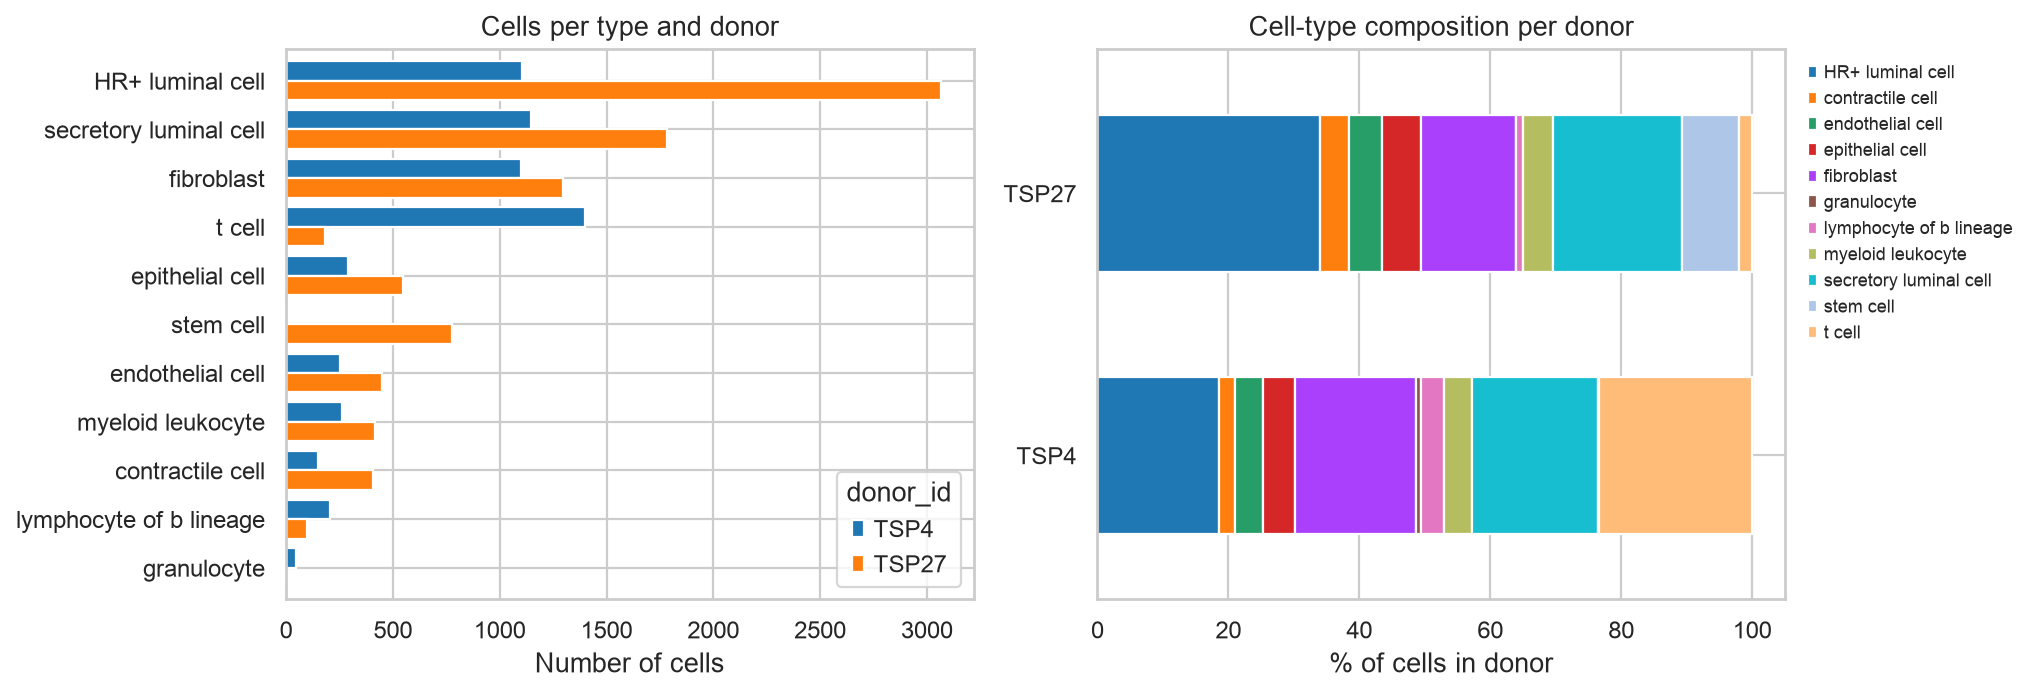

In [13]:
ct_by_donor = pd.crosstab(adata.obs["cell_type"], adata.obs["donor_id"])     # number of cells
ct_by_donor_pct = 100 * ct_by_donor / ct_by_donor.sum(axis=0)                 # % within each donor

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: absolute numbers per donor (grouped bars)
ct_by_donor.loc[ct_counts.index].plot.barh(ax=axes[0], color=DONOR_COLORS, width=0.8)
axes[0].invert_yaxis()
axes[0].set_xlabel("Number of cells")
axes[0].set_ylabel("")
axes[0].set_title("Cells per type and donor")

# Right: composition of each donor (stacked % bars)
# (we reuse the cell-type colours stored in adata.uns, so the colours match the UMAP plots later on)
CT_COLORS = dict(zip(adata.obs["cell_type"].cat.categories, adata.uns["cell_type_colors"]))
ct_by_donor_pct.T.plot.barh(stacked=True, ax=axes[1], width=0.6,
                            color=[CT_COLORS[c] for c in ct_by_donor_pct.index])
axes[1].set_xlabel("% of cells in donor")
axes[1].set_ylabel("")
axes[1].set_title("Cell-type composition per donor")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Observations**

* The two donors have quite different compositions: e.g. most **T cells** come from TSP4, while **stem cells** (luminal progenitors)
  are found almost only in TSP27.
* Differences like these may be biological (age, hormonal status, sampled region) or technical (dissociation, sampling).
* Important consequence: if cell type and donor are confounded, a classifier might learn **donor-specific** signals instead of
  cell-type signals. Splitting train/test **by donor** is a good way to test generalisation.

## 3. Exploring the count matrix

### 3.1 Sparsity

In [14]:
n_cells, n_genes = adata.shape
n_nonzero = adata.X.nnz                       # number of stored (non-zero) entries
sparsity = 1 - n_nonzero / (n_cells * n_genes)
print(f"{n_cells} cells x {n_genes} genes = {n_cells * n_genes:,} entries")
print(f"Non-zero entries: {n_nonzero:,}")
print(f"Fraction of zeros (sparsity): {sparsity:.1%}")

dense_gb = n_cells * n_genes * 4 / 1e9
sparse_gb = (adata.X.data.nbytes + adata.X.indices.nbytes + adata.X.indptr.nbytes) / 1e9
print(f"Memory as dense float32: {dense_gb:.2f} GB   vs   as sparse: {sparse_gb:.2f} GB")

14994 cells x 40377 genes = 605,412,738 entries
Non-zero entries: 50,022,624
Fraction of zeros (sparsity): 91.7%
Memory as dense float32: 2.42 GB   vs   as sparse: 0.40 GB


### 3.2 Per-cell metrics: library size and genes detected

Two basic per-cell quantities:

* **Library size** (`total_counts`): total number of UMIs captured in a cell = sum of its row. It depends on cell size and RNA content,
  but also strongly on **technical** factors (capture efficiency, sequencing depth). This is why we will need **normalisation**.
* **Number of genes detected** (`n_genes_by_counts`): number of genes with at least 1 count in the cell.

We compute them directly from the matrix with numpy, to see that they are just row sums:

In [15]:
# Sum over genes (axis=1) -> one value per cell. np.ravel() turns the result into a simple 1D array.
lib_size = np.ravel(adata.X.sum(axis=1))
genes_detected = np.ravel((adata.X > 0).sum(axis=1))      # number of genes with a count > 0

print("Library size: median =", np.median(lib_size), " min =", lib_size.min(), " max =", lib_size.max())
print("Genes detected: median =", np.median(genes_detected), " min =", genes_detected.min(), " max =", genes_detected.max())

Library size: median = 7631.0  min = 2510  max = 296718
Genes detected: median = 2908.5  min = 440  max = 13016


`scanpy` provides `sc.pp.calculate_qc_metrics`, which computes these and many more metrics at once. We also flag three gene groups
that are informative for quality control:

* **Mitochondrial genes** (`MT-` prefix): a high fraction of mitochondrial reads often indicates a damaged/dying cell —
  cytoplasmic mRNA leaks out of a broken membrane, while mitochondrial transcripts (protected inside mitochondria) remain.
* **Ribosomal protein genes** (`RPS`, `RPL`): very highly expressed; their fraction varies with cell type and cell state.
* **Haemoglobin genes** (`HB*`): indicate contamination with red blood cells.

In [16]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*$")
print(adata.var[["mt", "ribo", "hb"]].sum())

# Adds per-cell metrics to obs (overwriting existing columns with the same name) and per-gene metrics to var
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], percent_top=[20], log1p=True, inplace=True)

qc_cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb", "pct_counts_in_top_20_genes"]
adata.obs[qc_cols].describe().round(2)

mt        37
ribo    1162
hb         8
dtype: int64


,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_in_top_20_genes
count,14994.00,14994.00,14994.00,14994.00,14994.00,14994.00
mean,11620.37,3336.18,4.76,14.11,0.00,17.89
std,12413.32,1630.02,2.73,6.87,0.36,7.48
min,2510.00,440.00,0.00,0.24,0.00,7.65
25%,4502.00,2081.00,2.99,9.34,0.00,14.27
50%,7631.00,2908.50,4.31,13.26,0.00,16.62
75%,14504.75,4258.00,6.04,18.30,0.00,19.11
max,296718.00,13016.00,74.38,58.14,43.88,85.71


### 3.3 Comparing library sizes between donors and samples

Library sizes span **two orders of magnitude**, so we plot them on a **log scale**.

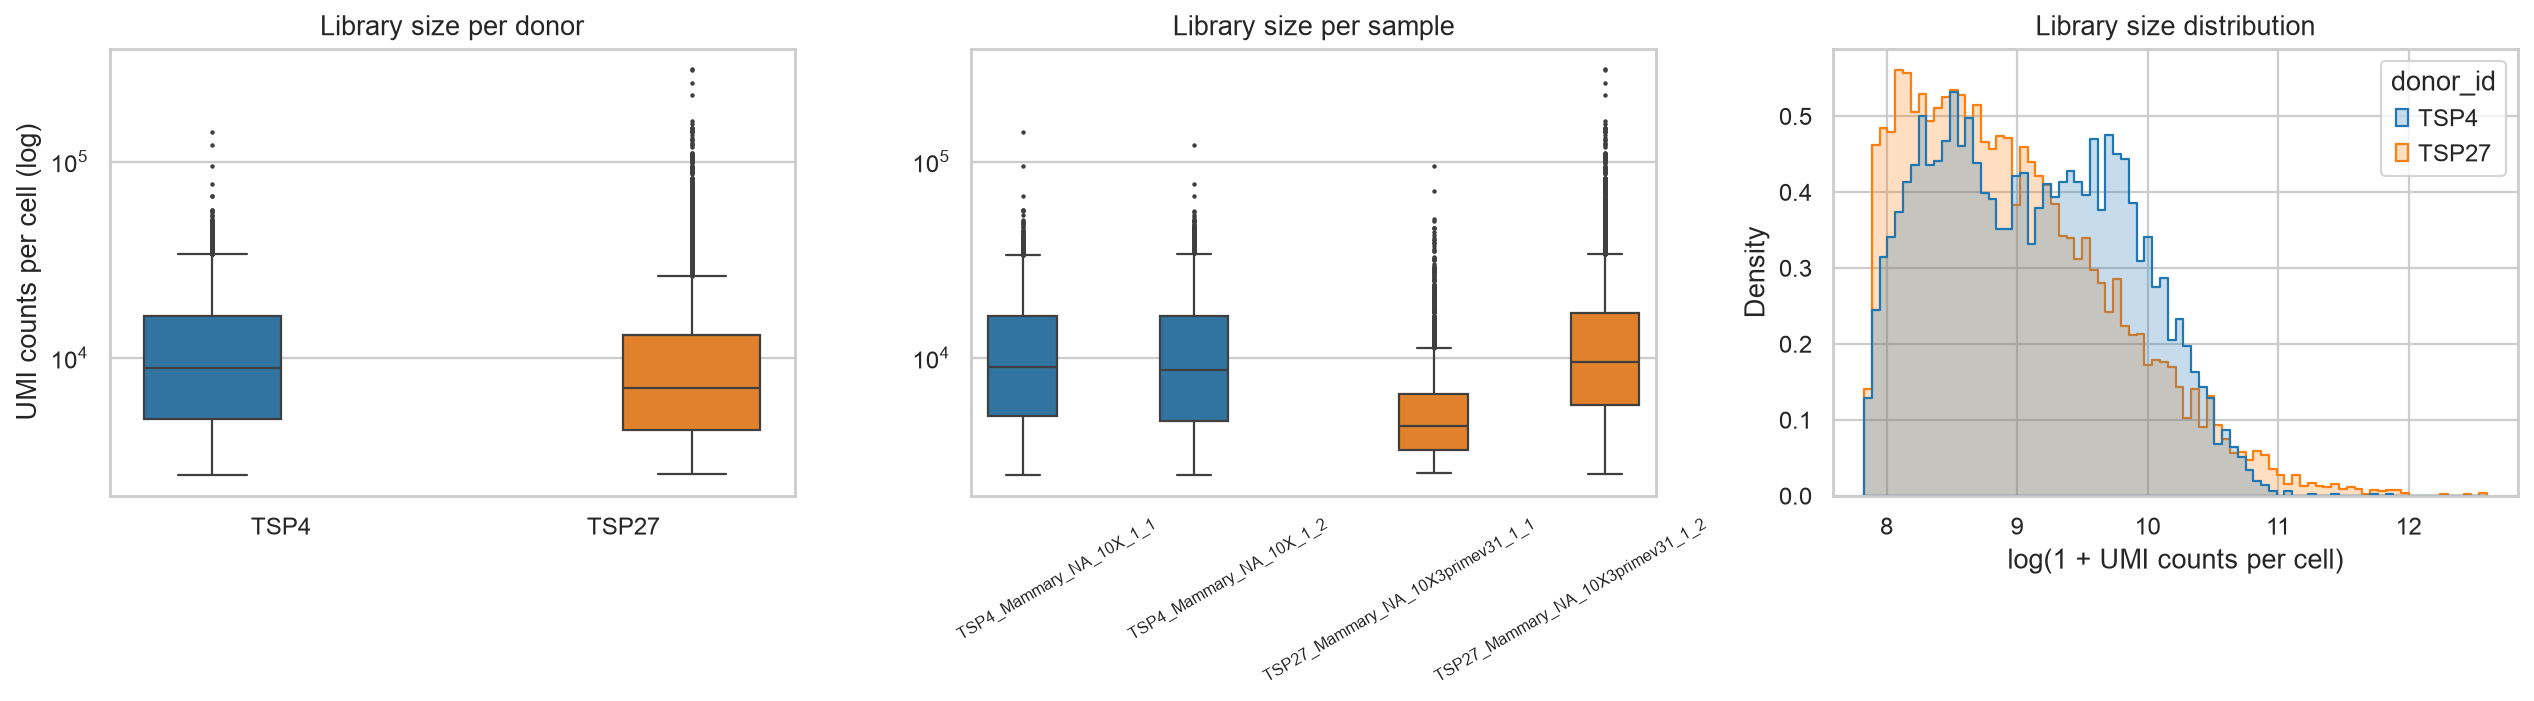

,count,mean,std,min,25%,50%,75%,max
donor_id,,,,,,,,
TSP4,5966.0,11898.0,9401.0,2510.0,4889.0,8830.0,16368.0,142098.0
TSP27,9028.0,11437.0,14051.0,2551.0,4282.0,7030.0,13049.0,296718.0


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Boxplot per donor
sns.boxplot(data=adata.obs, x="donor_id", y="total_counts", hue="donor_id", palette=DONOR_COLORS,
            ax=axes[0], fliersize=1, legend=False)
axes[0].set(yscale="log", title="Library size per donor", xlabel="", ylabel="UMI counts per cell (log)")

# Boxplot per sample (10x run)
sns.boxplot(data=adata.obs, x="sample_id", y="total_counts", hue="donor_id", palette=DONOR_COLORS,
            ax=axes[1], fliersize=1, legend=False)
axes[1].set(yscale="log", title="Library size per sample", xlabel="", ylabel="")
axes[1].tick_params(axis="x", rotation=30, labelsize=7)

# Distribution (histogram) per donor on log10 scale
sns.histplot(data=adata.obs, x="log1p_total_counts", hue="donor_id", palette=DONOR_COLORS,
             element="step", stat="density", common_norm=False, bins=80, ax=axes[2])
axes[2].set(title="Library size distribution", xlabel="log(1 + UMI counts per cell)")
plt.tight_layout()
plt.show()

adata.obs.groupby("donor_id", observed=True)["total_counts"].describe().round(0)

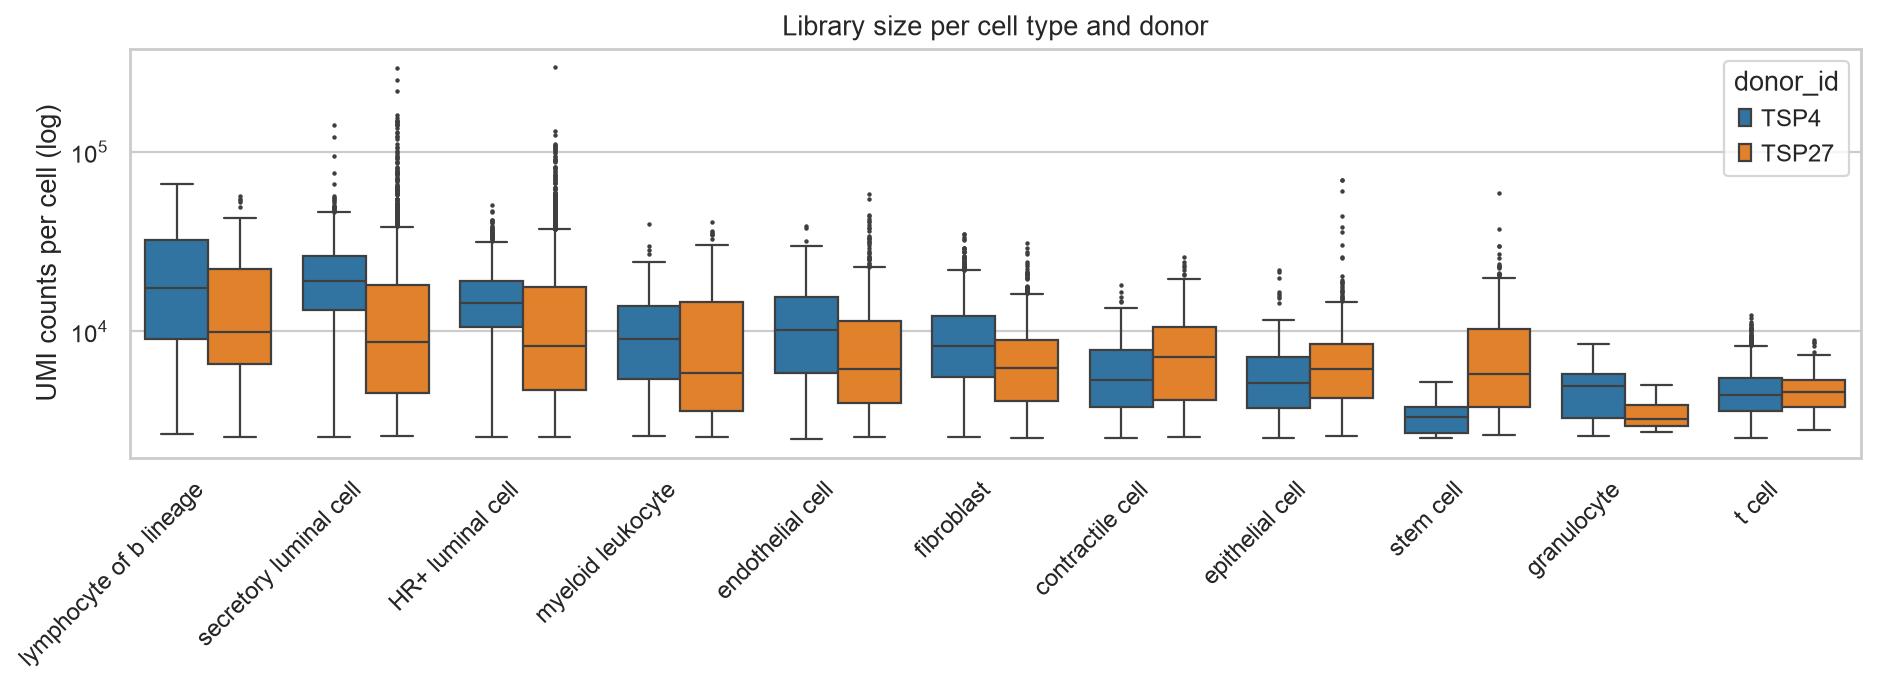

In [18]:
# Library size also depends strongly on the cell type (larger / more active cells have more mRNA)
order = adata.obs.groupby("cell_type", observed=True)["total_counts"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=adata.obs, x="cell_type", y="total_counts", hue="donor_id", order=order, palette=DONOR_COLORS,
            fliersize=1, ax=ax)
ax.set(yscale="log", xlabel="", ylabel="UMI counts per cell (log)", title="Library size per cell type and donor")
ax.tick_params(axis="x", rotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

**Observations**

* Median library size differs between donors **and** between the two runs of the same donor → technical variation.
* Library size also differs systematically between cell types (e.g. epithelial cells vs. T cells). So library size is a mix of biology and
  technique — another reason why normalisation is needed before comparing cells.

### 3.4 Genes detected per cell

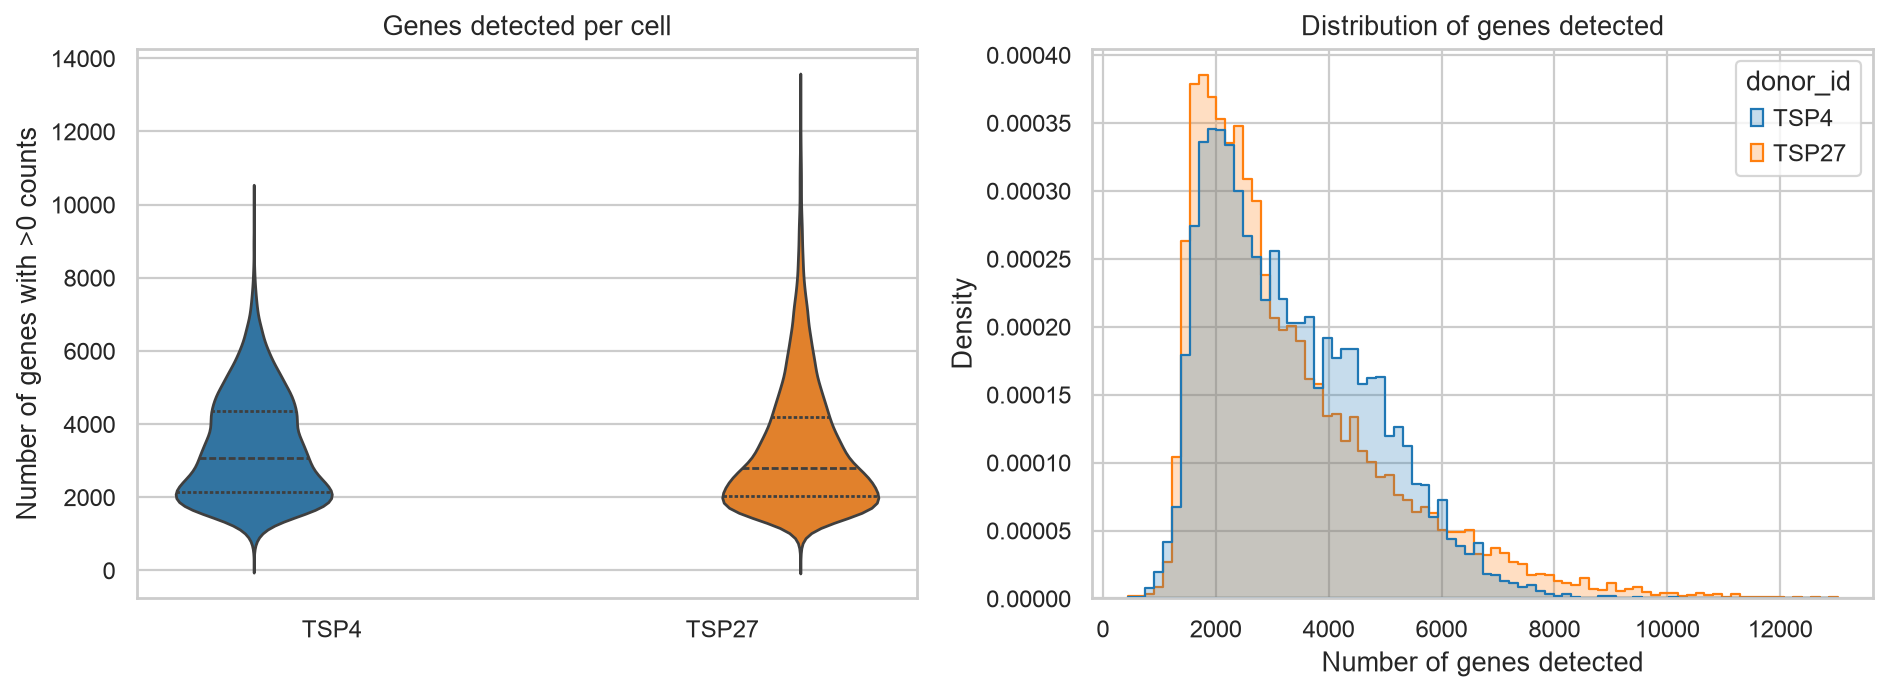

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.violinplot(data=adata.obs, x="donor_id", y="n_genes_by_counts", hue="donor_id", palette=DONOR_COLORS,
               inner="quartile", ax=axes[0], legend=False)
axes[0].set(title="Genes detected per cell", xlabel="", ylabel="Number of genes with >0 counts")

sns.histplot(data=adata.obs, x="n_genes_by_counts", hue="donor_id", palette=DONOR_COLORS, element="step",
             stat="density", common_norm=False, bins=80, ax=axes[1])
axes[1].set(title="Distribution of genes detected", xlabel="Number of genes detected")
plt.tight_layout()
plt.show()

### 3.5 Mean–variance relationship

A key statistical property of count data: genes with a **higher mean** also have a **higher variance**. For a Poisson distribution
variance = mean; scRNA-seq counts are usually **overdispersed** (variance > mean), better described by a negative binomial distribution.
This is why we cannot simply compare raw variances between genes and why a **variance-stabilising transformation**
(like the log transform used below) is applied.

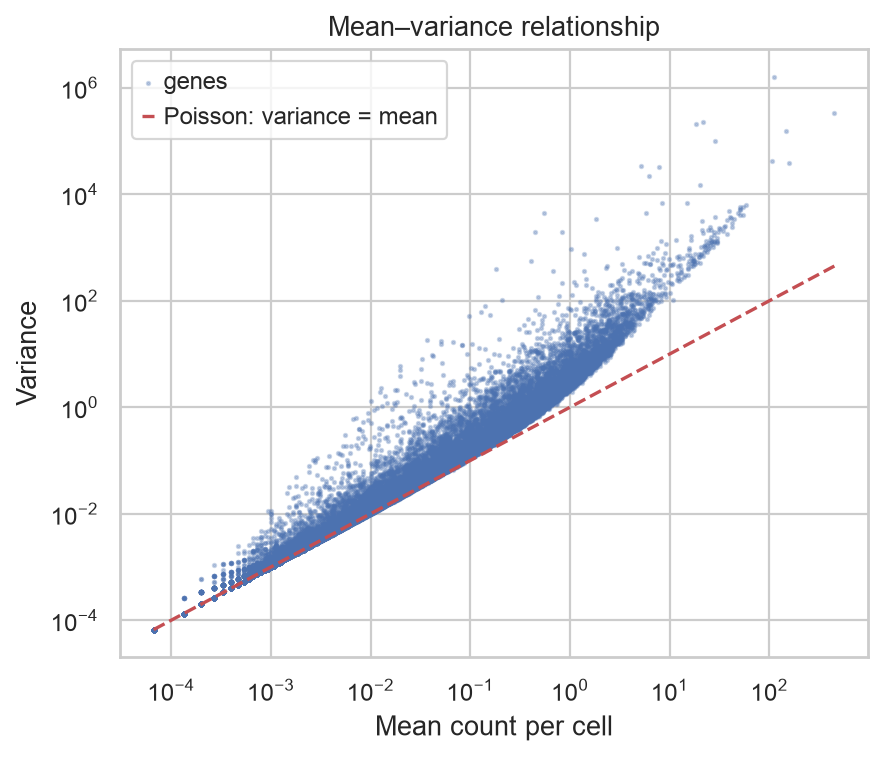

In [20]:
# Mean and variance of every gene across cells (axis=0 = over the rows/cells)
gene_mean = np.ravel(adata.X.mean(axis=0))
gene_var = np.ravel(adata.X.power(2).mean(axis=0)) - gene_mean**2     # Var(x) = mean(x^2) - mean(x)^2

# Keep only genes detected at least once (a mean of 0 cannot be shown on a log scale)
detected = gene_mean > 0
gene_mean, gene_var = gene_mean[detected], gene_var[detected]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(gene_mean, gene_var, s=2, alpha=0.3, rasterized=True, label="genes")
xx = np.logspace(np.log10(gene_mean.min()), np.log10(gene_mean.max()), 100)
ax.plot(xx, xx, "r--", label="Poisson: variance = mean")
ax.set(xscale="log", yscale="log", xlabel="Mean count per cell", ylabel="Variance", title="Mean–variance relationship")
ax.legend()
plt.show()

## 4. Quality control (QC) and filtering

The aim of QC is to remove:

* **Low-quality / empty droplets**: very few counts and genes (the droplet captured little or no RNA, or a broken cell).
* **Dying / damaged cells**: high fraction of mitochondrial counts.
* **Potential doublets**: droplets containing two cells, which have an unusually high number of genes.
  (Dedicated tools such as `scrublet` detect doublets better; here we only use a simple upper threshold.)
* **Uninformative genes**: genes detected in very few cells.

> This dataset was **already filtered** by the authors (note the minimum of ~400 genes per cell), so we expect to remove only a small
> number of cells. In a raw dataset the effect of QC would be much larger.

We use simple **fixed thresholds**, chosen by looking at the distributions (red dashed lines below).

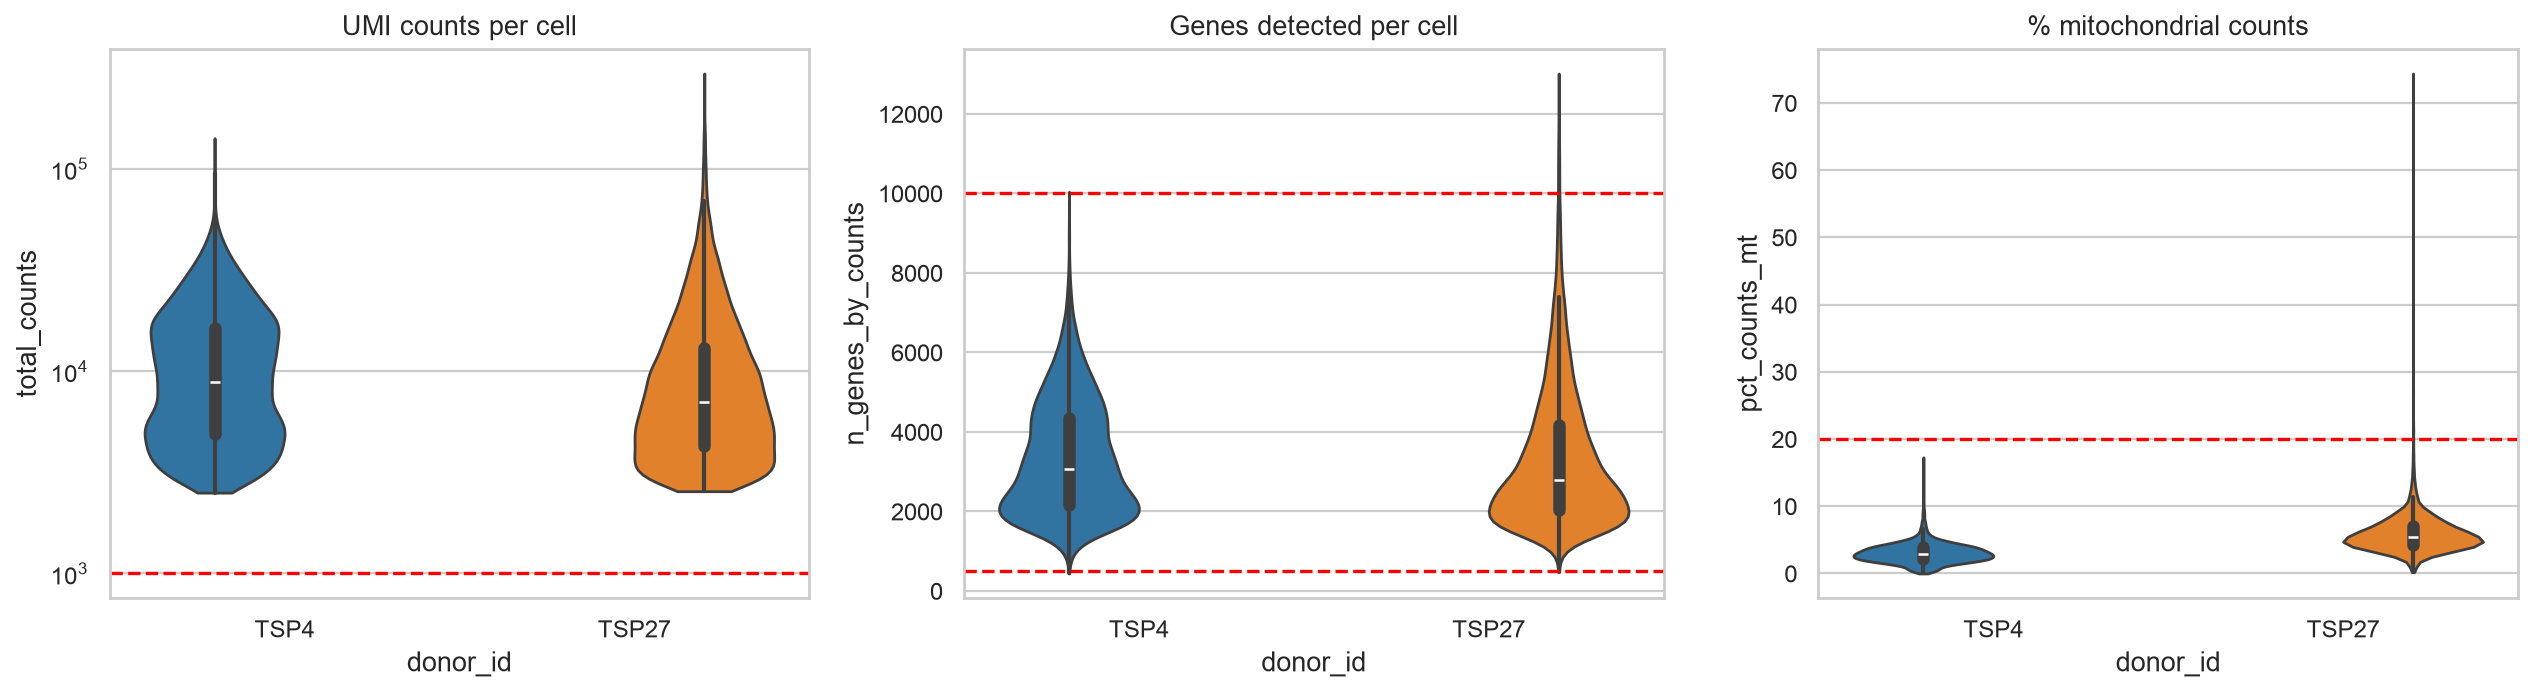

In [21]:
# ---- QC thresholds (feel free to experiment with these values!) ----
MIN_GENES = 500        # minimum number of genes detected per cell
MAX_GENES = 10000      # maximum number of genes detected per cell (possible doublets)
MIN_COUNTS = 1000      # minimum library size
MAX_PCT_MT = 20        # maximum % of mitochondrial counts
MIN_CELLS = 10         # a gene must be detected in at least this many cells

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.violinplot(data=adata.obs, x="donor_id", y="total_counts", hue="donor_id", palette=DONOR_COLORS,
               log_scale=True, cut=0, ax=axes[0], legend=False)
axes[0].axhline(MIN_COUNTS, color="red", ls="--")
axes[0].set_title("UMI counts per cell")

sns.violinplot(data=adata.obs, x="donor_id", y="n_genes_by_counts", hue="donor_id", palette=DONOR_COLORS,
               cut=0, ax=axes[1], legend=False)
axes[1].axhline(MIN_GENES, color="red", ls="--")
axes[1].axhline(MAX_GENES, color="red", ls="--")
axes[1].set_title("Genes detected per cell")

sns.violinplot(data=adata.obs, x="donor_id", y="pct_counts_mt", hue="donor_id", palette=DONOR_COLORS,
               cut=0, ax=axes[2], legend=False)
axes[2].axhline(MAX_PCT_MT, color="red", ls="--")
axes[2].set_title("% mitochondrial counts")

plt.tight_layout()
plt.show()

In [22]:
# One True/False value per cell for each criterion (True = the cell fails)
too_few_genes = adata.obs["n_genes_by_counts"] < MIN_GENES
too_many_genes = adata.obs["n_genes_by_counts"] > MAX_GENES
too_few_counts = adata.obs["total_counts"] < MIN_COUNTS
too_much_mt = adata.obs["pct_counts_mt"] > MAX_PCT_MT

# A cell is removed if it fails at least one criterion
adata.obs["qc_fail"] = too_few_genes | too_many_genes | too_few_counts | too_much_mt

# How many cells fail each criterion?
pd.Series({
    f"genes < {MIN_GENES}": too_few_genes.sum(),
    f"genes > {MAX_GENES}": too_many_genes.sum(),
    f"counts < {MIN_COUNTS}": too_few_counts.sum(),
    f"% mito > {MAX_PCT_MT}": too_much_mt.sum(),
    "removed (any criterion)": adata.obs["qc_fail"].sum(),
}).to_frame("n_cells")

,n_cells
genes < 500,2
genes > 10000,50
counts < 1000,0
% mito > 20,20
removed (any criterion),72


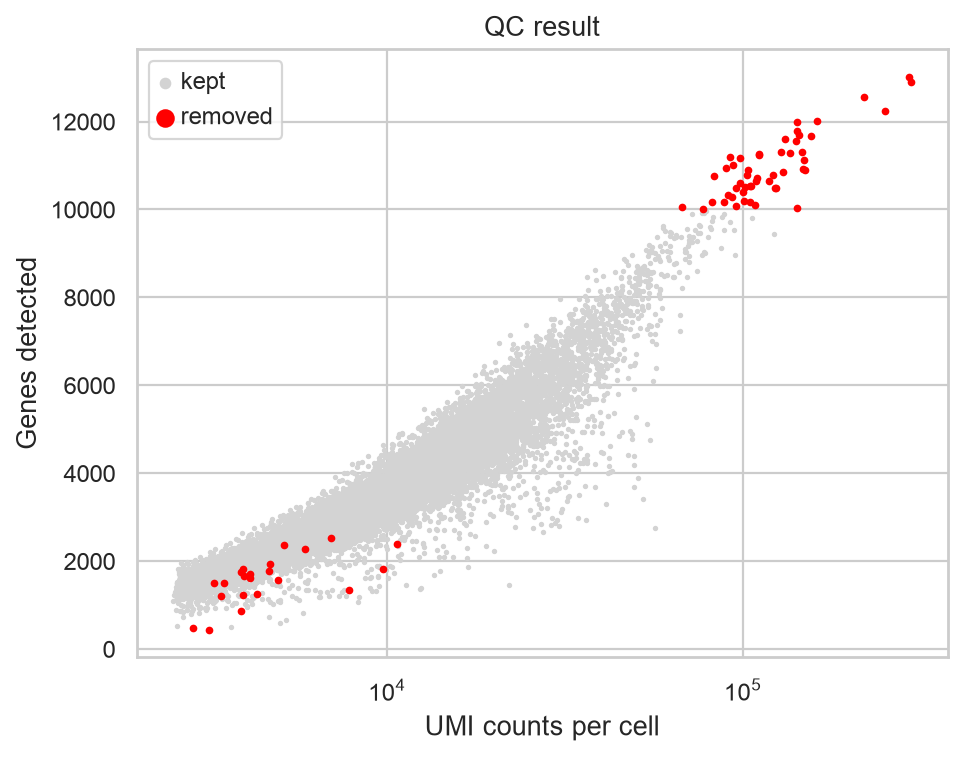

In [23]:
# Where are the removed cells in the counts-vs-genes plot?
kept = adata.obs[~adata.obs["qc_fail"]]
removed = adata.obs[adata.obs["qc_fail"]]

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(kept["total_counts"], kept["n_genes_by_counts"], s=2, c="lightgrey", label="kept")
ax.scatter(removed["total_counts"], removed["n_genes_by_counts"], s=6, c="red", label="removed")
ax.set(xscale="log", xlabel="UMI counts per cell", ylabel="Genes detected", title="QC result")
ax.legend(markerscale=3)
plt.show()

In [24]:
# Which cell types lose cells?
pd.crosstab(adata.obs["cell_type"], adata.obs["qc_fail"]).rename(columns={False: "kept", True: "removed"})

qc_fail,kept,removed
cell_type,,
HR+ luminal cell,4142,29
contractile cell,557,1
endothelial cell,701,0
epithelial cell,839,0
fibroblast,2393,6
granulocyte,49,0
lymphocyte of b lineage,301,5
myeloid leukocyte,675,1
secretory luminal cell,2898,30


> **Careful:** QC thresholds should not remove whole cell types. Some cell types naturally have small libraries (e.g. lymphocytes) or high
> mitochondrial content (e.g. very metabolically active cells). Always check *which* cells you remove.

Now we apply the filters to cells and genes.

In [25]:
print(f"Before filtering: {adata.n_obs} cells, {adata.n_vars} genes")

adata = adata[~adata.obs["qc_fail"]].copy()           # keep only the cells that pass QC
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)         # remove genes detected in fewer than MIN_CELLS cells

print(f"After filtering:  {adata.n_obs} cells, {adata.n_vars} genes")

Before filtering: 14994 cells, 40377 genes


After filtering:  14922 cells, 30497 genes


## 5. Normalisation, feature selection and dimensionality reduction

### 5.1 Why not use the raw counts directly?

Let's see what happens if we run PCA directly on the raw counts, without any preprocessing.

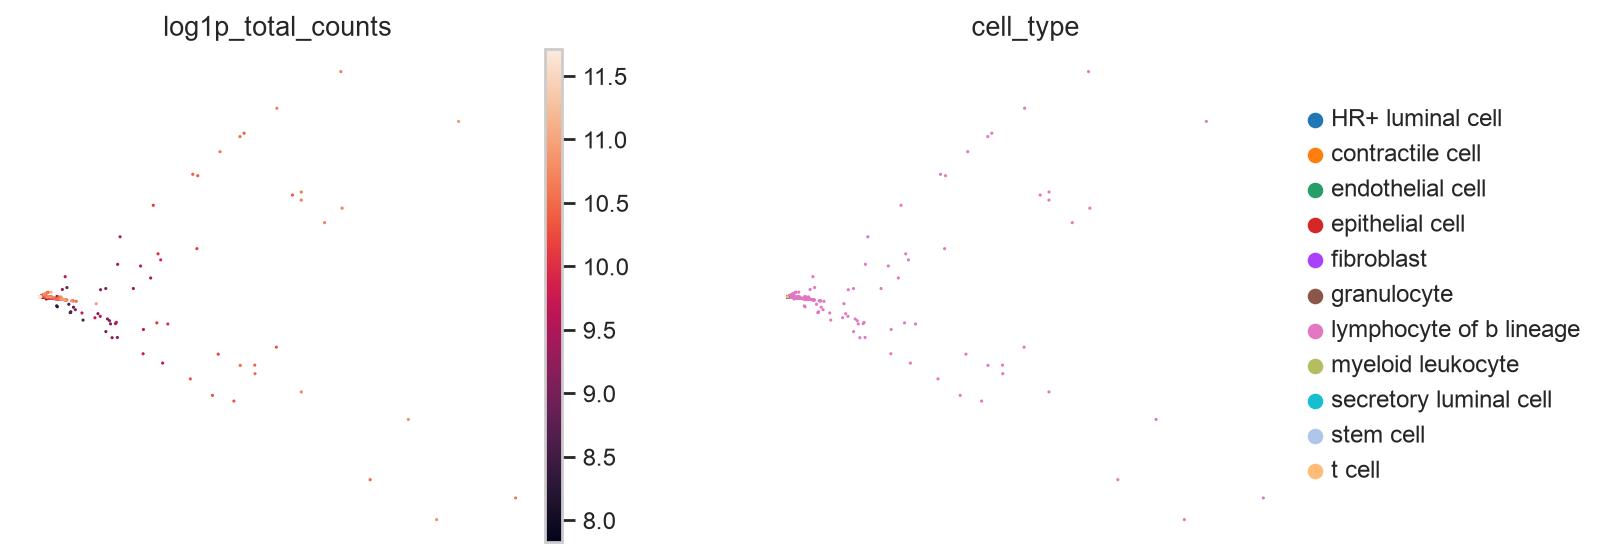

In [26]:
# Keep a copy of the raw counts: normalisation will overwrite X
adata.layers["counts"] = adata.X.copy()

# PCA on a copy of the data with the raw counts (no normalisation, no log), just for illustration
adata_raw = adata.copy()
sc.tl.pca(adata_raw, n_comps=20, random_state=SEED)
sc.pl.pca(adata_raw, color=["log1p_total_counts", "cell_type"], size=8, wspace=0.3)

In [27]:
# Which genes contribute most to PC1? (largest loadings, stored in .varm["PCs"])
pc1_loadings = pd.Series(adata_raw.varm["PCs"][:, 0], index=adata_raw.var_names)
pc1_loadings.abs().sort_values(ascending=False).head(5)

IGLC2    0.737932
IGLC3    0.625892
IGHA1    0.223752
IGHA2    0.085598
IGHG1    0.061864
dtype: float64

Without any preprocessing the PCA is useless: most cells are squashed into a corner, and the first PCs are driven by a **few cells
with huge library sizes** and by a **handful of extremely abundant genes** (raw variance grows with the mean, so the most highly
expressed genes dominate). Cell types are barely separated. Here PC1 is essentially "how many immunoglobulin transcripts (`IGLC2`, `IGHA1`, ...) does a
cell have" — i.e. it only separates the plasma cells, which produce enormous amounts of antibody mRNA. The standard preprocessing pipeline is:

1. **Normalise** each cell to the same total count (e.g. 10,000), to remove differences in sequencing depth / capture efficiency.
2. **Log-transform**: `log(1 + x)`. Stabilises the variance (see the mean–variance plot) and makes the distributions less skewed.
3. **Select highly variable genes (HVGs)**: keep the ~2,000 genes that vary most across cells, they carry most of the biological signal.
4. **Scale** each gene to mean 0 and variance 1 (z-score), so that every gene contributes equally to the PCA.
5. **PCA** to reduce to ~30–50 dimensions.
6. Build a **k-nearest-neighbour graph** in PCA space and compute a **UMAP** for 2D visualisation.

### 5.2 Normalisation and log-transform

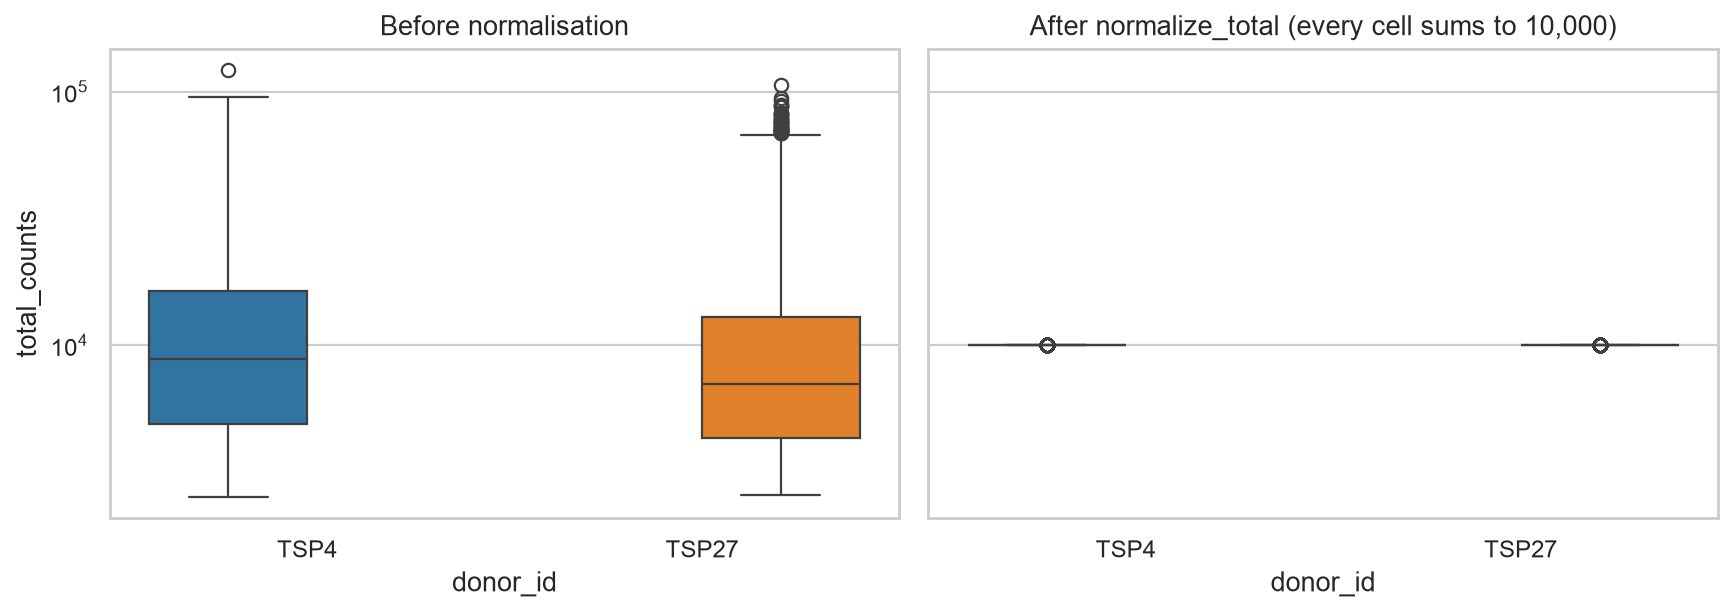

In [28]:
sc.pp.normalize_total(adata, target_sum=1e4)   # counts per 10,000 ("CP10k")
adata.obs["total_counts_normalised"] = np.ravel(adata.X.sum(axis=1))   # library size after normalisation
sc.pp.log1p(adata)                             # natural log(1 + x)

# Effect on library sizes: after normalisation every cell has the same total
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.boxplot(data=adata.obs, x="donor_id", y="total_counts", hue="donor_id", palette=DONOR_COLORS,
            log_scale=True, ax=axes[0], legend=False)
axes[0].set_title("Before normalisation")
sns.boxplot(data=adata.obs, x="donor_id", y="total_counts_normalised", hue="donor_id", palette=DONOR_COLORS,
            ax=axes[1], legend=False)
axes[1].set_title("After normalize_total (every cell sums to 10,000)")
plt.tight_layout()
plt.show()

### 5.3 Highly variable genes

`sc.pp.highly_variable_genes` bins genes by mean expression and, within each bin, picks genes whose dispersion (variance/mean)
is high compared with genes of similar mean. Using `batch_key="sample_id"` selects HVGs within each sample and favours genes that are
variable in several samples — this reduces the influence of genes that differ only because of the batch.

Number of HVGs: 2000


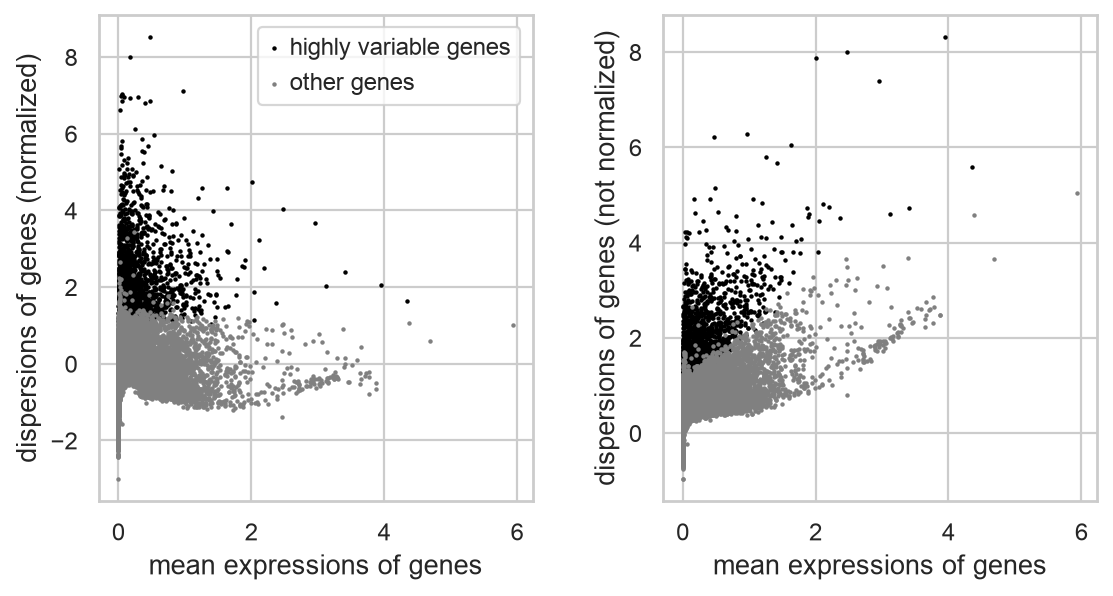

In [29]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="sample_id")
print("Number of HVGs:", adata.var["highly_variable"].sum())
sc.pl.highly_variable_genes(adata)

In [30]:
# Which are the most variable genes? Many of them should be cell-type markers.
adata.var.loc[adata.var["highly_variable"]].sort_values("dispersions_norm", ascending=False).head(25).index.tolist()

['IGLL5',
 'IGHG4',
 'IGHG1',
 'IGLV2-23',
 'IGHV3-7',
 'IGLV2-8',
 'CPB1',
 'PRG4',
 'IGHG2',
 'IGHGP',
 'IGLV2-11',
 'IGHG3',
 'IGLV1-44',
 'TPSB2',
 'FDCSP',
 'HSPA6',
 'IGHV3-23',
 'IGKV3-20',
 'PTX3',
 'IGKV4-1',
 'S100A8',
 'KRT81',
 'CCL21',
 'CXCL5',
 'SCGB1B2P']

### 5.4 Scaling and PCA

Scaling makes the matrix **dense**, so we do it on a copy containing only the HVGs (2,000 genes instead of ~25,000).
Values are clipped at 10 standard deviations to limit the influence of extreme outliers.

In [31]:
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50, random_state=SEED)

# Copy the PCA results back into the full object
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.uns["pca"] = adata_hvg.uns["pca"]

/usr/local/Cellar/python@3.13/3.13.0_1/Frameworks/Python.framework/Versions/3.13/lib/python3.13/functools.py:929: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


**How many PCs to keep?** The *elbow plot* shows the variance explained by each PC. After a certain number of components the curve
flattens: the remaining PCs mostly capture noise.

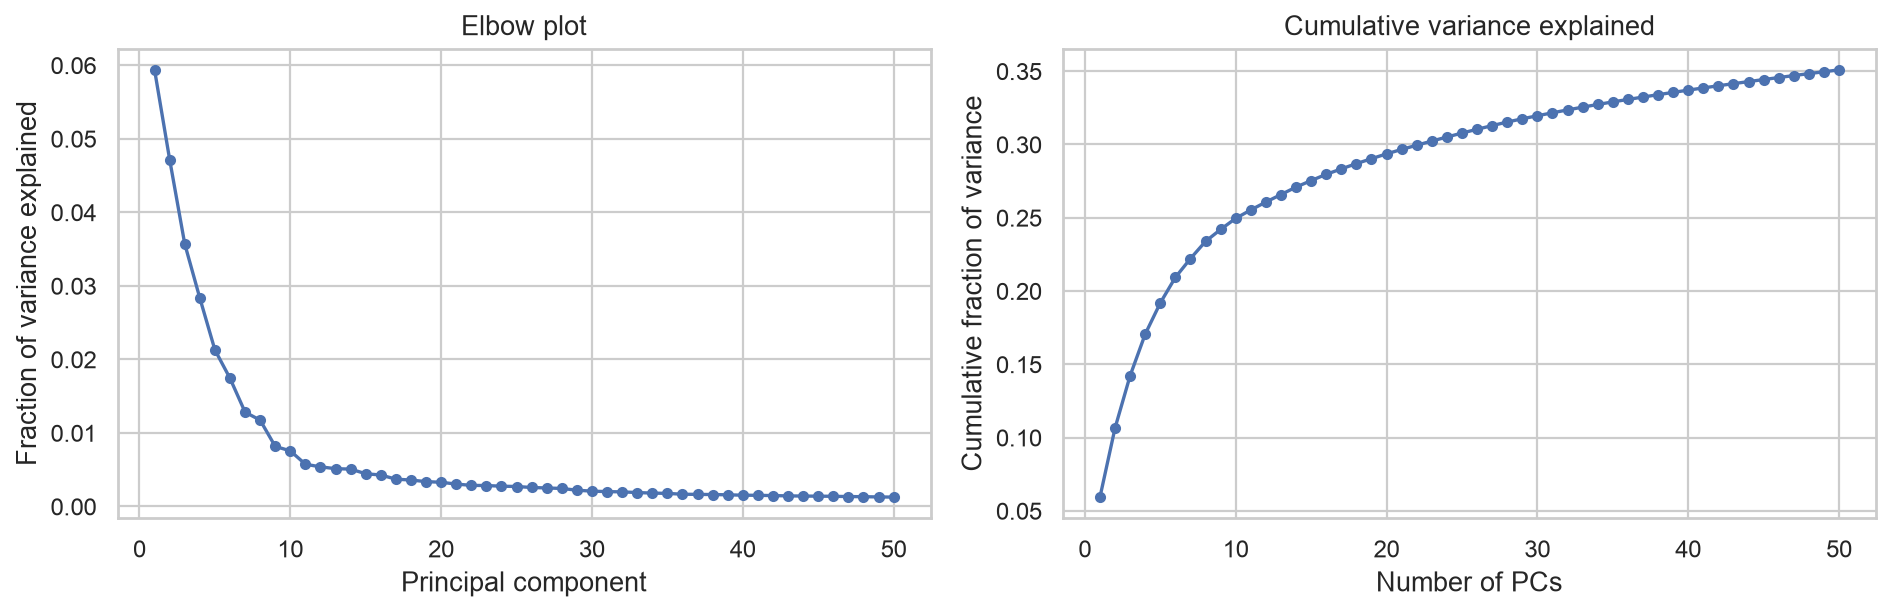

In [32]:
var_ratio = adata.uns["pca"]["variance_ratio"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, 51), var_ratio, "o-", ms=4)
axes[0].set(xlabel="Principal component", ylabel="Fraction of variance explained", title="Elbow plot")
axes[1].plot(np.arange(1, 51), np.cumsum(var_ratio), "o-", ms=4)
axes[1].set(xlabel="Number of PCs", ylabel="Cumulative fraction of variance", title="Cumulative variance explained")
plt.tight_layout()
plt.show()

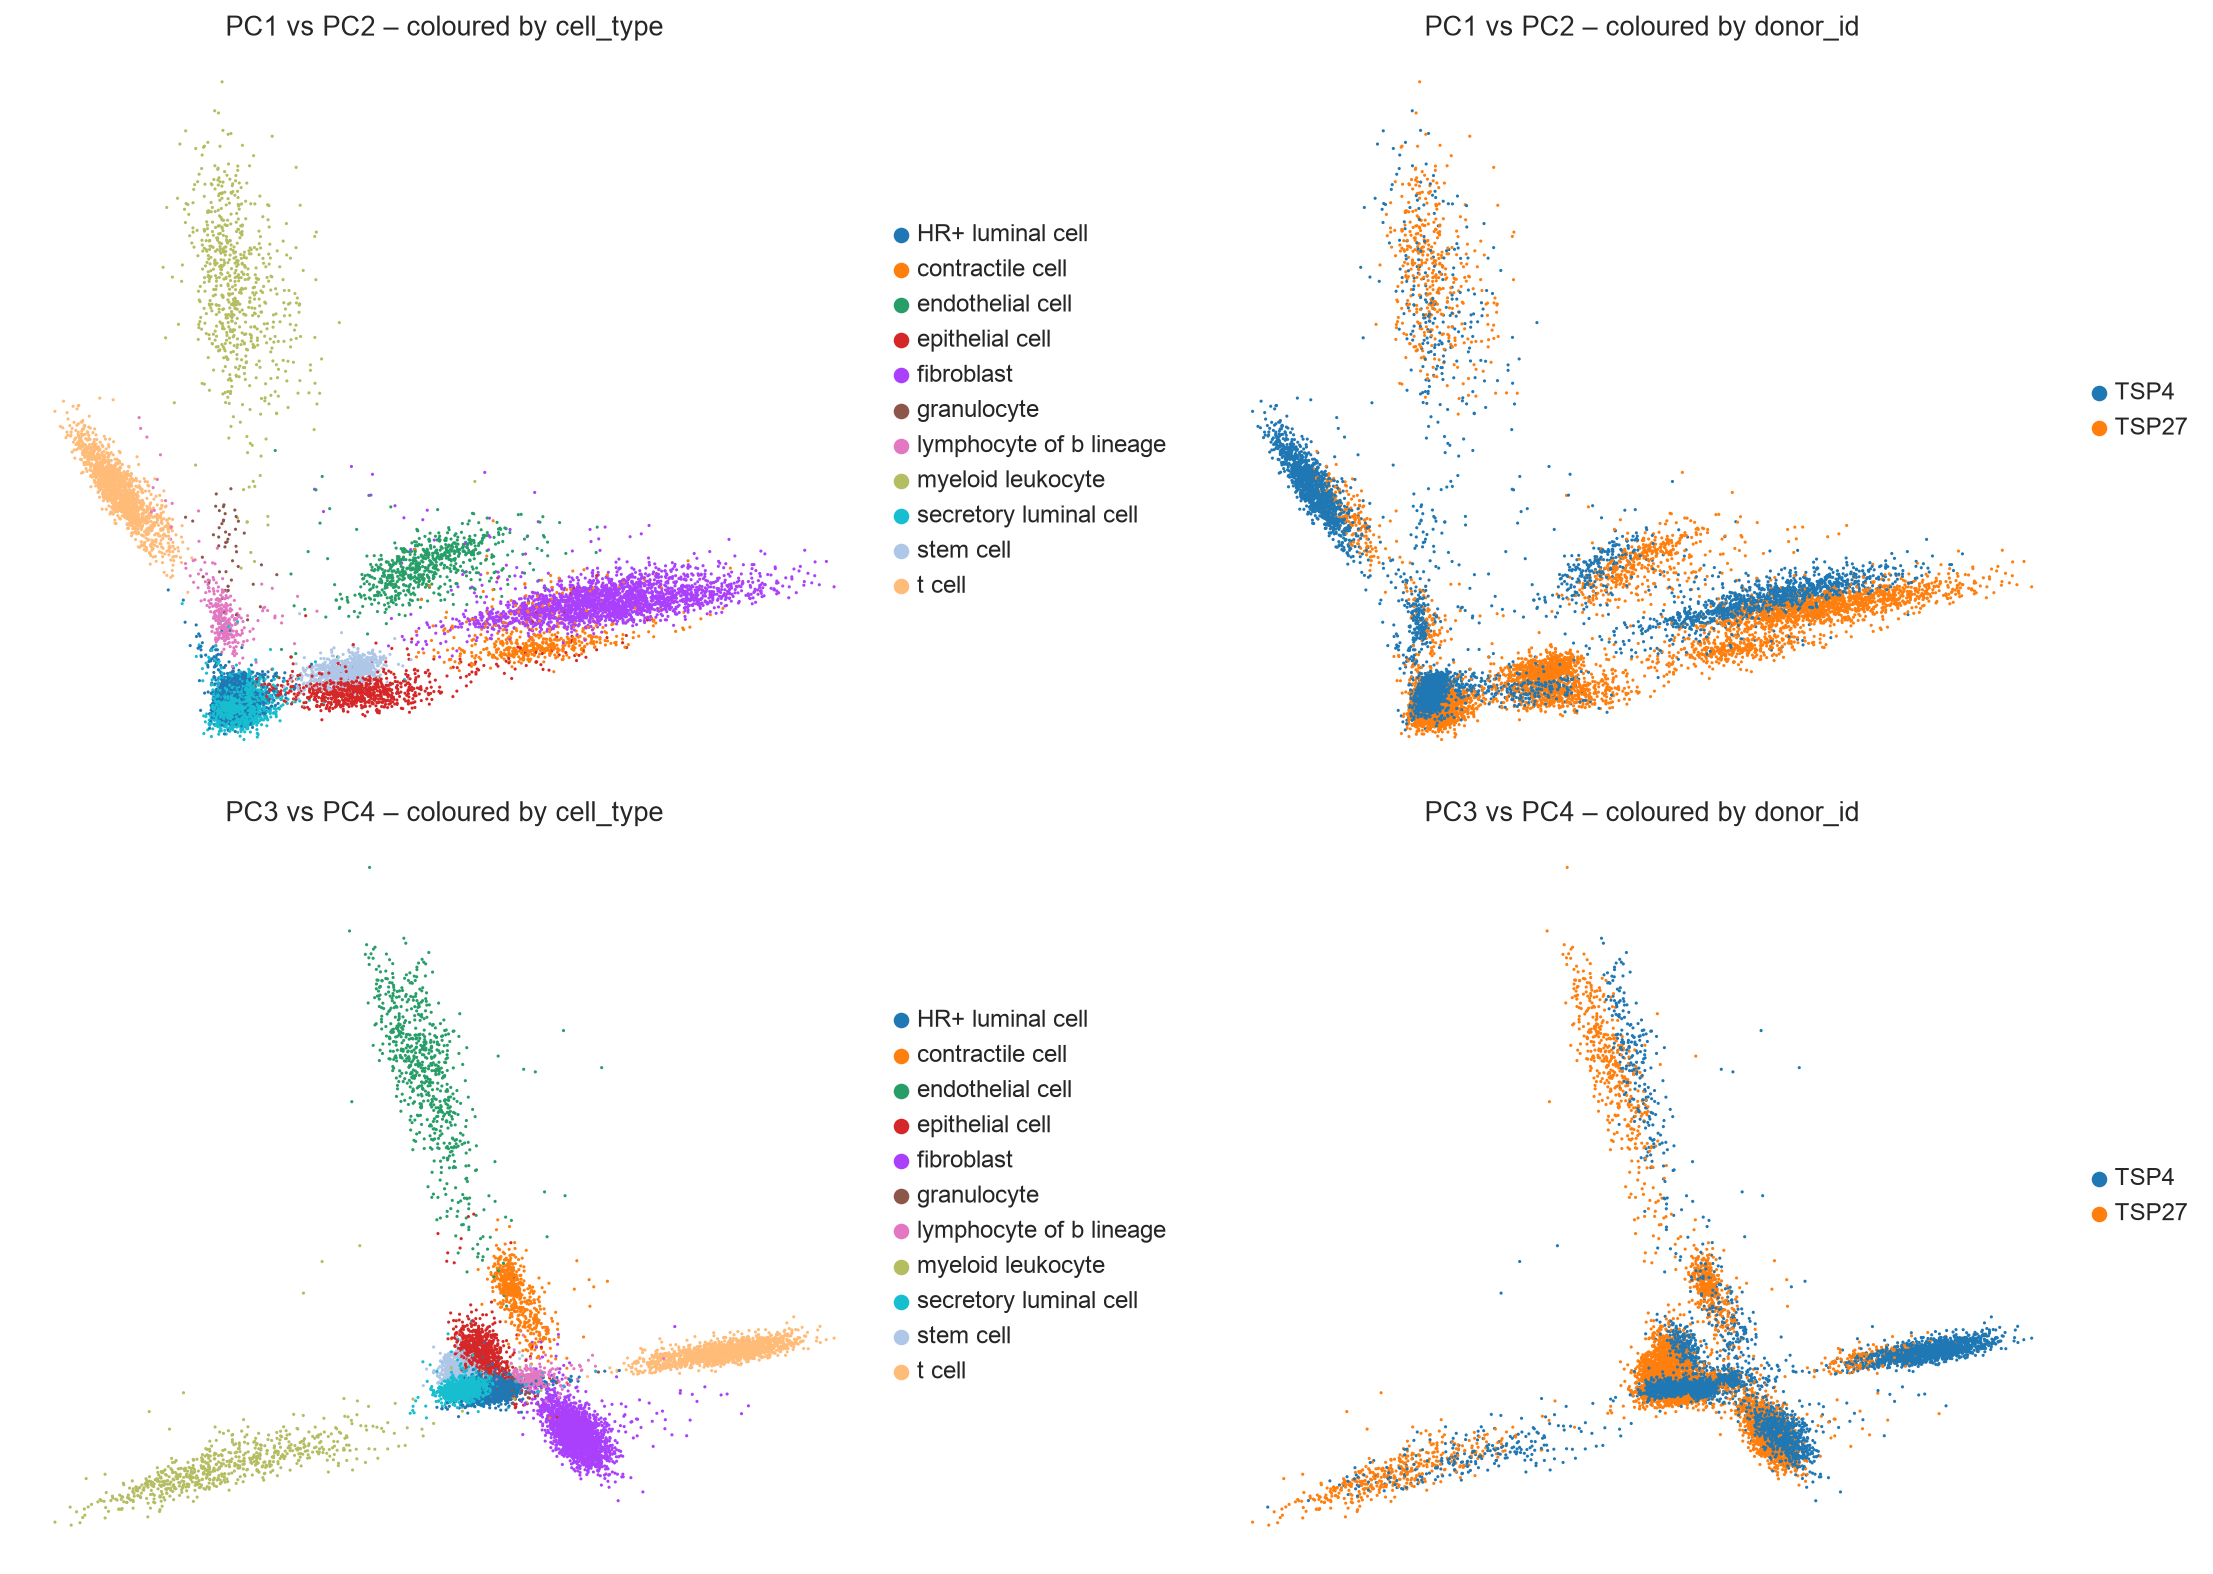

In [33]:
# First PCs coloured by cell type (left) and donor (right).
# Top row: PC1 vs PC2, bottom row: PC3 vs PC4
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, comps in enumerate(["1,2", "3,4"]):
    pc_x, pc_y = comps.split(",")
    for col, color in enumerate(["cell_type", "donor_id"]):
        sc.pl.pca(adata, color=color, components=comps, ax=axes[row, col], show=False, size=8,
                  title=f"PC{pc_x} vs PC{pc_y} – coloured by {color}")
plt.tight_layout()
plt.show()

### 5.5 Neighbourhood graph and UMAP

**UMAP** (Uniform Manifold Approximation and Projection) is a non-linear method that embeds cells in 2D while trying to preserve
their **local neighbourhoods**. It works in two steps: build a k-nearest-neighbour (kNN) graph in PCA space, then optimise a 2D layout
that keeps neighbours close.

> **How to read a UMAP:** cells that are close are similar. However, **distances between clusters**, cluster **sizes** and **shapes**
> are not reliably interpretable. UMAP is for visualisation, not for quantitative analysis.

In [34]:
N_PCS = 30          # number of PCs used, based on the elbow plot
N_NEIGHBORS = 15    # size of the local neighbourhood

sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

/private/tmp/claude-505/-Users-oscargonzalezvelasco-Desktop-ML-course-exerc-2026/67d03563-2d31-47bd-b418-7214693fbe0e/scratchpad/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


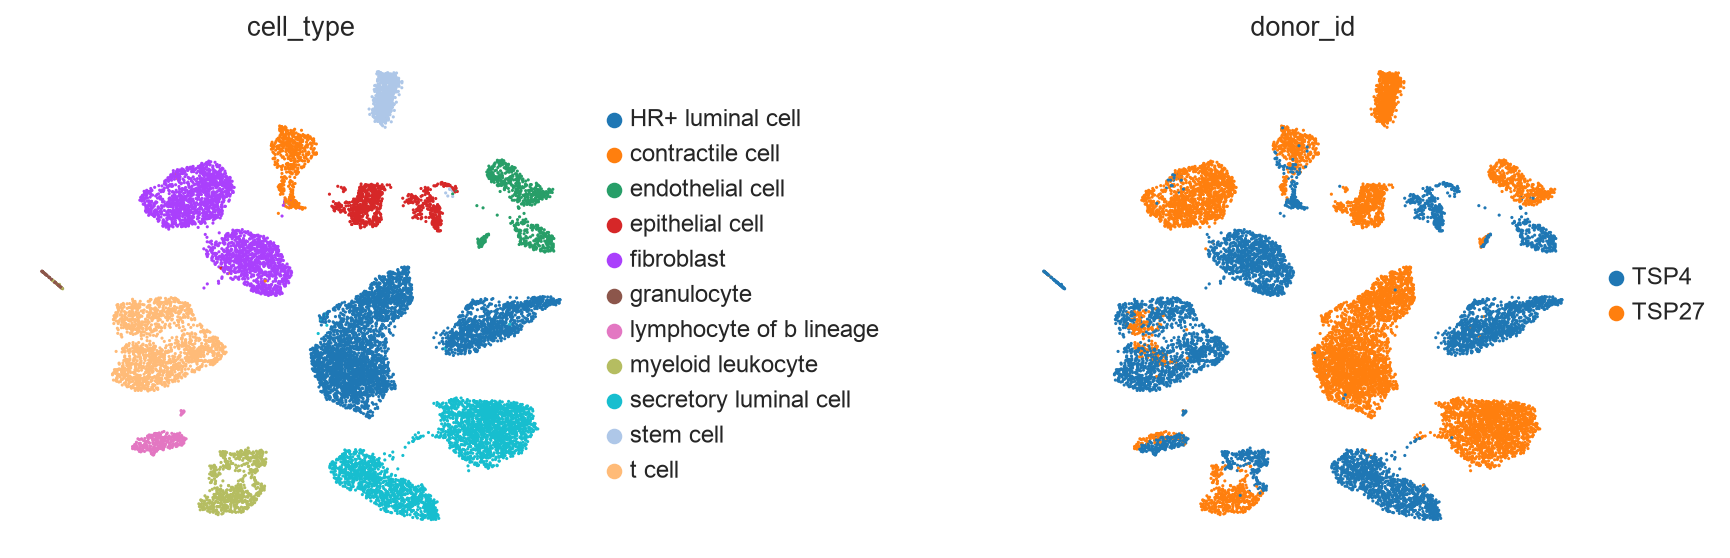

In [35]:
sc.pl.umap(adata, color=["cell_type", "donor_id"], palette=None, wspace=0.6, size=8)

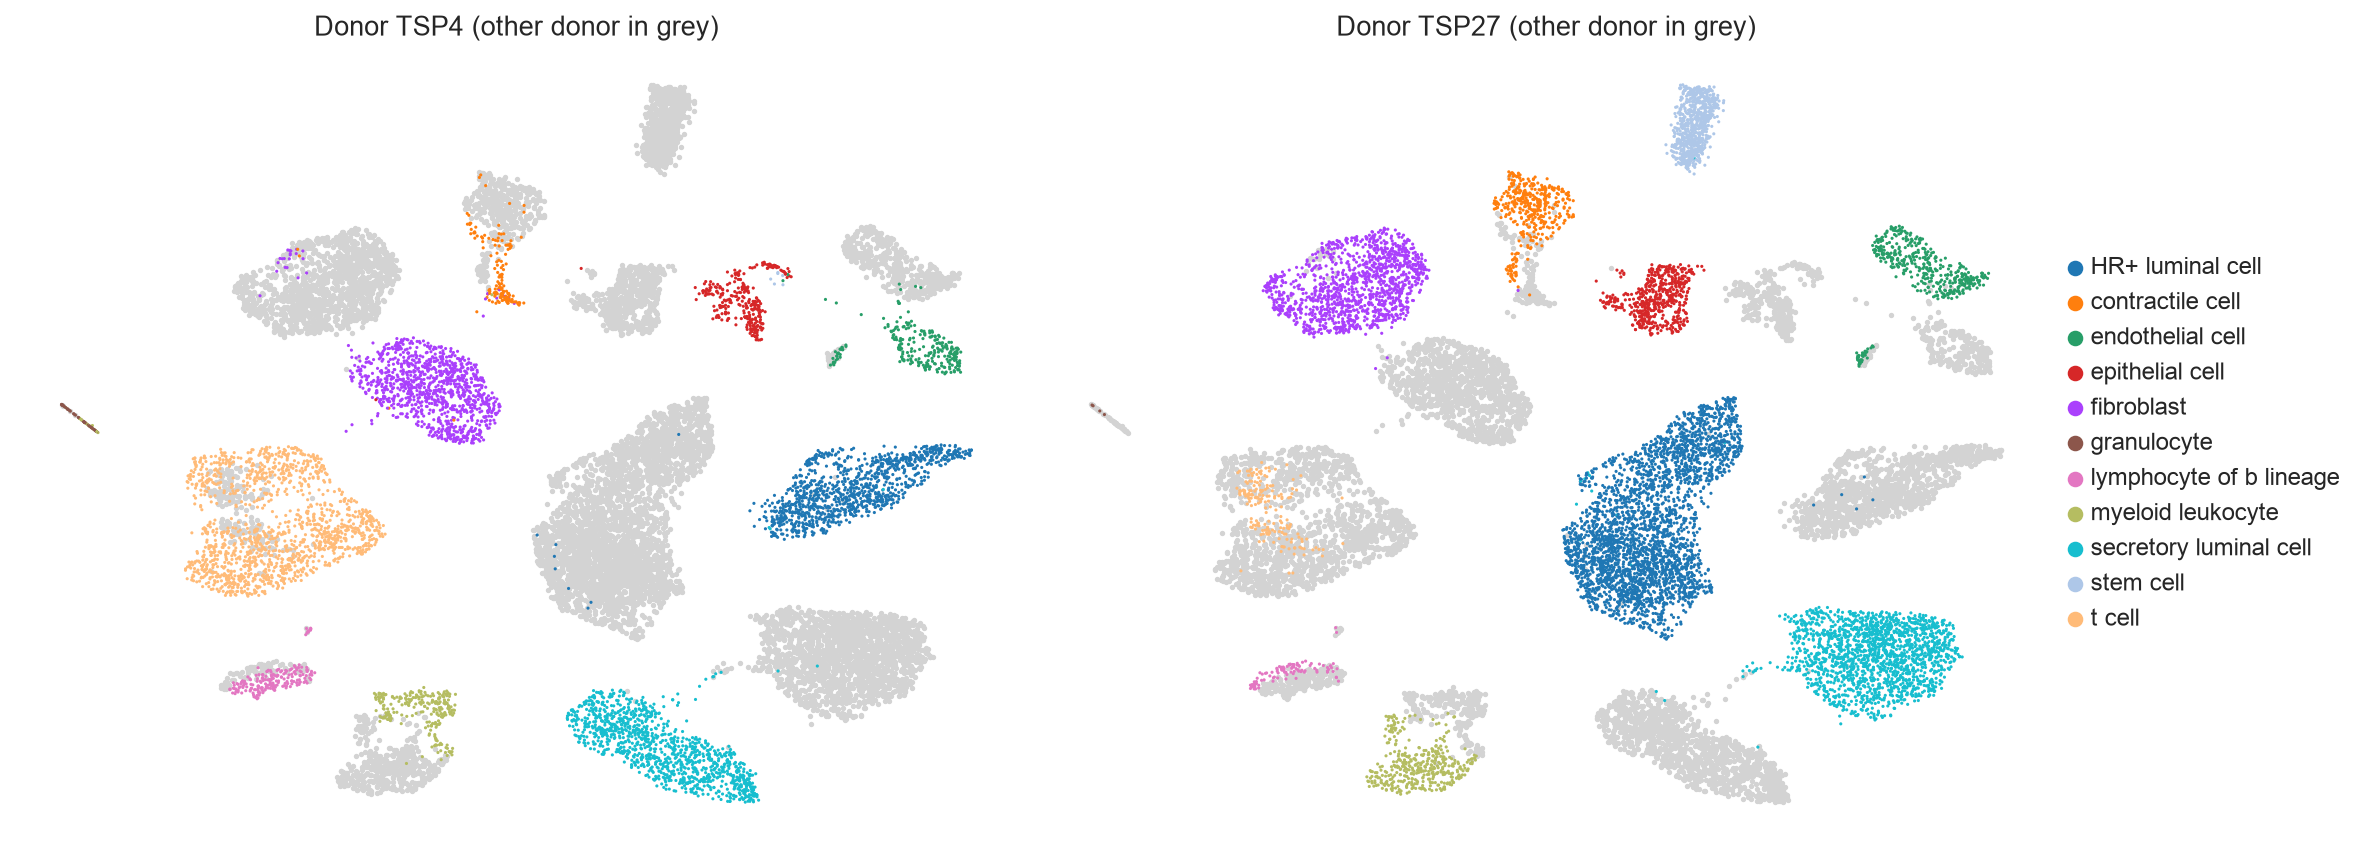

In [36]:
# One panel per donor: cells of that donor coloured by cell type, all other cells in grey.
# Do both donors contain the same cell types, and do they occupy the same regions?
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
umap = adata.obsm["X_umap"]
for ax, donor in zip(axes, ["TSP4", "TSP27"]):
    is_donor = (adata.obs["donor_id"] == donor).values
    ax.scatter(umap[~is_donor, 0], umap[~is_donor, 1], s=2, c="lightgrey", rasterized=True)
    sc.pl.umap(adata[is_donor], color="cell_type", ax=ax, show=False, size=8,
               title=f"Donor {donor} (other donor in grey)", legend_loc=None if donor == "TSP4" else "right margin")
plt.tight_layout()
plt.show()

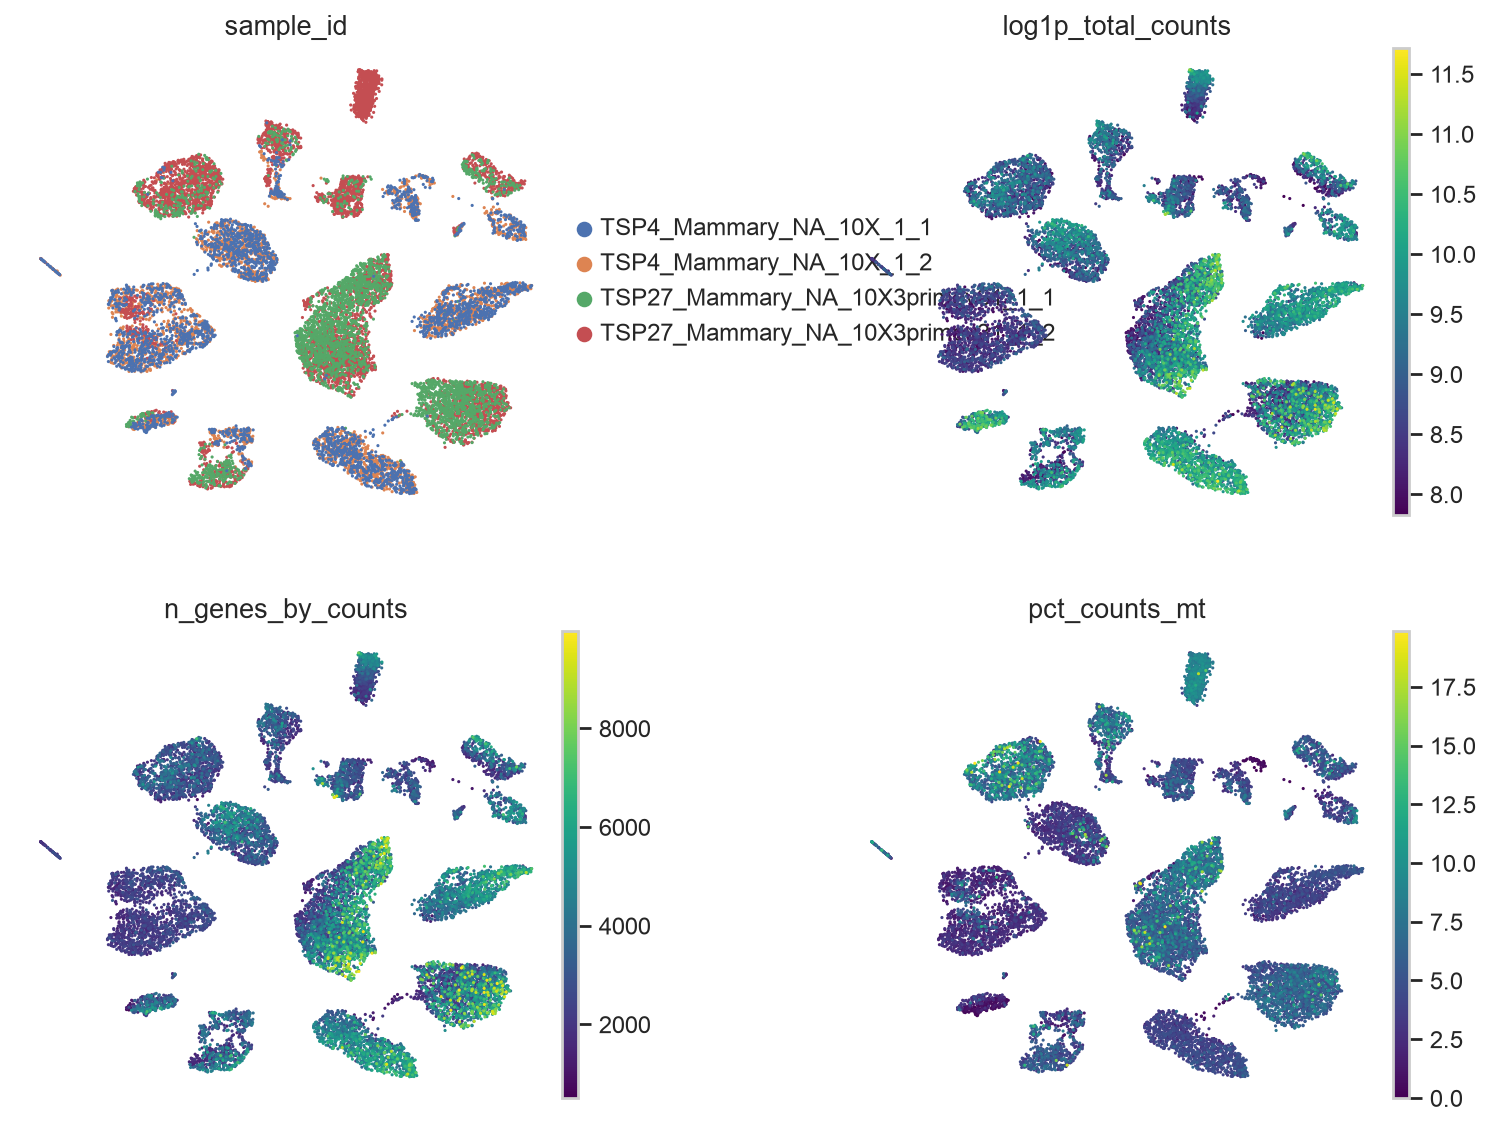

In [37]:
# Technical covariates on the UMAP: are there regions dominated by low-quality or high-count cells?
sc.pl.umap(adata, color=["sample_id", "log1p_total_counts", "n_genes_by_counts", "pct_counts_mt"],
           ncols=2, wspace=0.4, size=8, cmap="viridis")

**Observations**

* Cells group mostly by **cell type** — the annotations form clear islands. Epithelial, stromal, endothelial and immune compartments are
  well separated.
* Within some cell types, cells from the two donors occupy **partially separate regions** (e.g. the luminal cells). This is a
  **donor / batch effect**: part of the variation is explained by the donor rather than by the cell type.
* Technical covariates (library size, % mitochondrial) also show some structure. Some of this is biological (cell types differ in RNA
  content), but it is worth monitoring.

### 5.6 Comparison with the authors' embedding

The authors corrected the donor effect with an **integration** method ([Harmony](https://doi.org/10.1038/s41592-019-0619-0)), which
adjusts the PCA coordinates so that cells of the same type from different donors mix together. Let's compare their UMAP to ours.

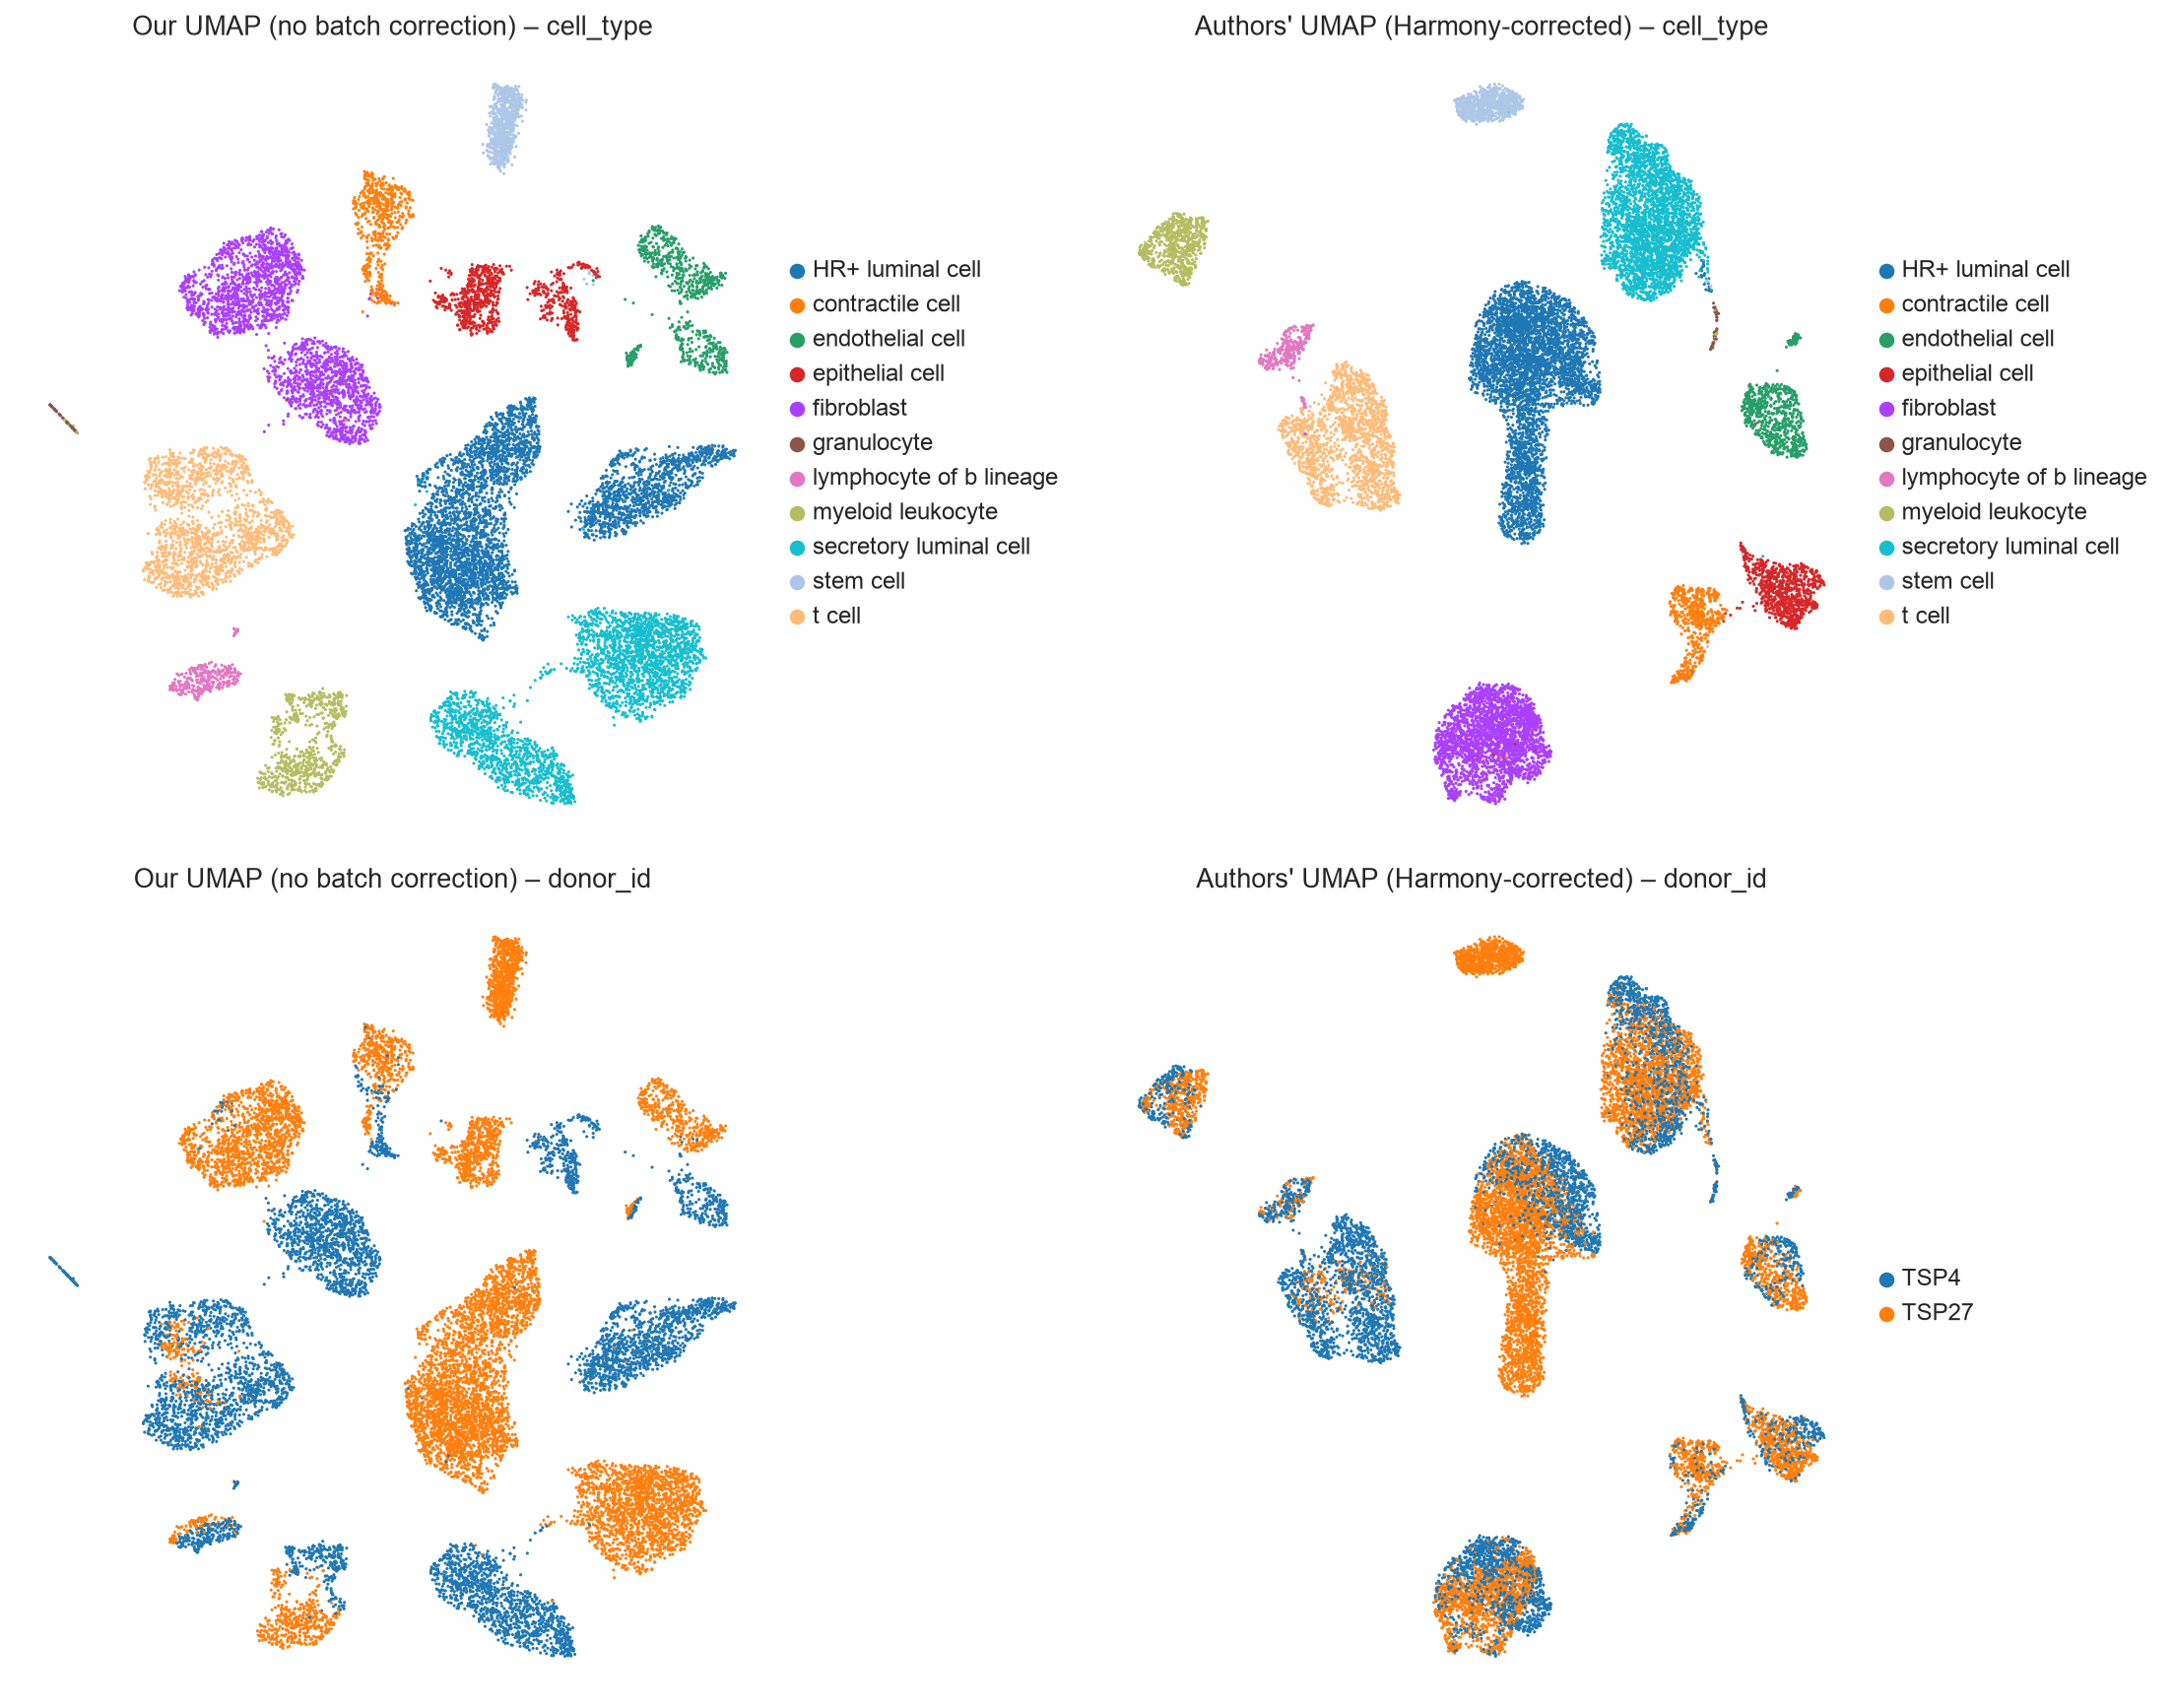

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for row, color in enumerate(["cell_type", "donor_id"]):
    sc.pl.embedding(adata, basis="X_umap", color=color, ax=axes[row, 0], show=False, size=8,
                    title=f"Our UMAP (no batch correction) – {color}", legend_loc="right margin" if row == 0 else None)
    sc.pl.embedding(adata, basis="X_umap_authors", color=color, ax=axes[row, 1], show=False, size=8,
                    title=f"Authors' UMAP (Harmony-corrected) – {color}",
                    legend_loc="right margin")
plt.tight_layout()
plt.show()

After Harmony, the two donors are much more mixed within each cell type. Batch correction is a topic of its own: it can remove technical
noise, but if done too aggressively it can also remove real biological differences.

## 6. Marker genes

**Marker genes** are genes that are specifically expressed in one cell type. They are how biologists annotate clusters. We start with
some well-known markers from the literature:

| cell type | markers |
|---|---|
| epithelial cells (all) | `EPCAM`, `KRT8`, `KRT18` |
| HR+ luminal (hormone-responsive) | `ESR1` (oestrogen receptor), `PGR` (progesterone receptor), `ANKRD30A`, `AR` |
| secretory luminal / luminal progenitor | `SLPI`, `LTF`, `KIT`, `ELF5` |
| basal / myoepithelial ("epithelial cell") | `KRT5`, `KRT14`, `KRT17`, `ACTA2` |
| fibroblast | `DCN`, `LUM`, `COL1A1` |
| endothelial | `PECAM1`, `VWF` |
| contractile (vascular smooth muscle / pericytes) | `MYH11`, `RGS5`, `ACTA2` |
| immune cells (all) | `PTPRC` (CD45) |
| T cells | `CD3E`, `CD2` |
| B lineage / plasma cells | `MS4A1`, `JCHAIN`, `MZB1` |
| myeloid (macrophages) | `C1QA`, `AIF1`, `LYZ` (classic markers such as `CD68` are poorly detected in this dataset) |
| granulocytes (mast cells / basophils) | `CPA3`, `TPSAB1` |

All plots below use the **log-normalised** expression in `adata.X`.

In [39]:
markers = {
    "Epithelial": ["EPCAM", "KRT8", "KRT18"],
    "HR+ luminal": ["ESR1", "PGR", "ANKRD30A", "AR"],
    "Secretory luminal": ["SLPI", "LTF", "KIT", "ELF5"],
    "Basal": ["KRT5", "KRT14", "KRT17"],
    "Fibroblast": ["DCN", "LUM", "COL1A1"],
    "Endothelial": ["PECAM1", "VWF"],
    "Contractile": ["ACTA2", "MYH11", "RGS5"],
    "Immune": ["PTPRC"],
    "T cell": ["CD3E", "CD2"],
    "B lineage": ["MS4A1", "JCHAIN", "MZB1"],
    "Myeloid": ["C1QA", "AIF1", "LYZ"],
    "Granulocyte": ["CPA3", "TPSAB1"],
}
# Sanity check: all genes are present (after gene filtering)
missing = [g for gs in markers.values() for g in gs if g not in adata.var_names]
print("Missing markers:", missing)

# Order cell types roughly by compartment so the dot plot reads as a diagonal
ct_order = ["HR+ luminal cell", "secretory luminal cell", "stem cell", "epithelial cell", "fibroblast",
            "contractile cell", "endothelial cell", "t cell", "lymphocyte of b lineage", "myeloid leukocyte", "granulocyte"]

Missing markers: []


### 6.1 Dot plot: many markers at once

A **dot plot** summarises two things per (gene, cell type): the **colour** is the mean expression and the **dot size** is the fraction
of cells in which the gene is detected. It is the standard compact way to show markers.
Expression is scaled per gene (`standard_scale="var"`) so that genes with very different expression levels can be compared.

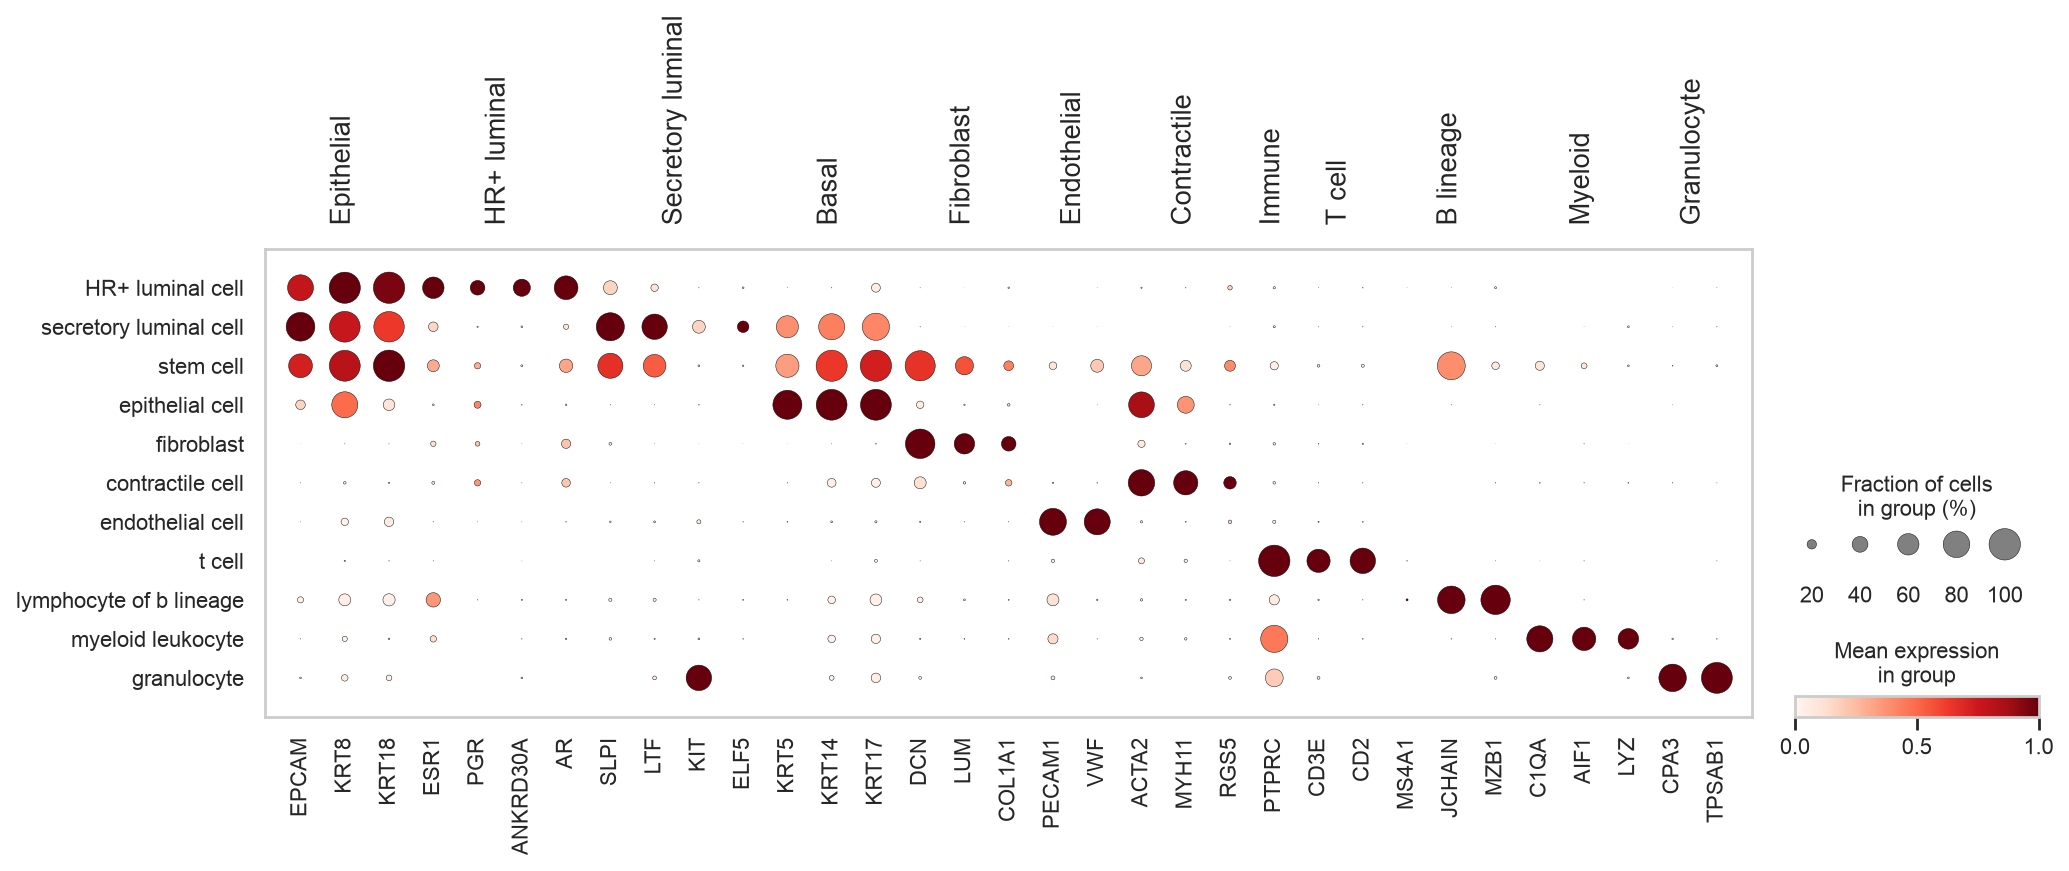

In [40]:
sc.pl.dotplot(adata, markers, groupby="cell_type", categories_order=ct_order, standard_scale="var", cmap="Reds")

### 6.2 Marker expression on the UMAP

We can also colour the UMAP by the expression of a single gene. `CD3E` is part of the T-cell receptor complex and should light up
only the T-cell island.

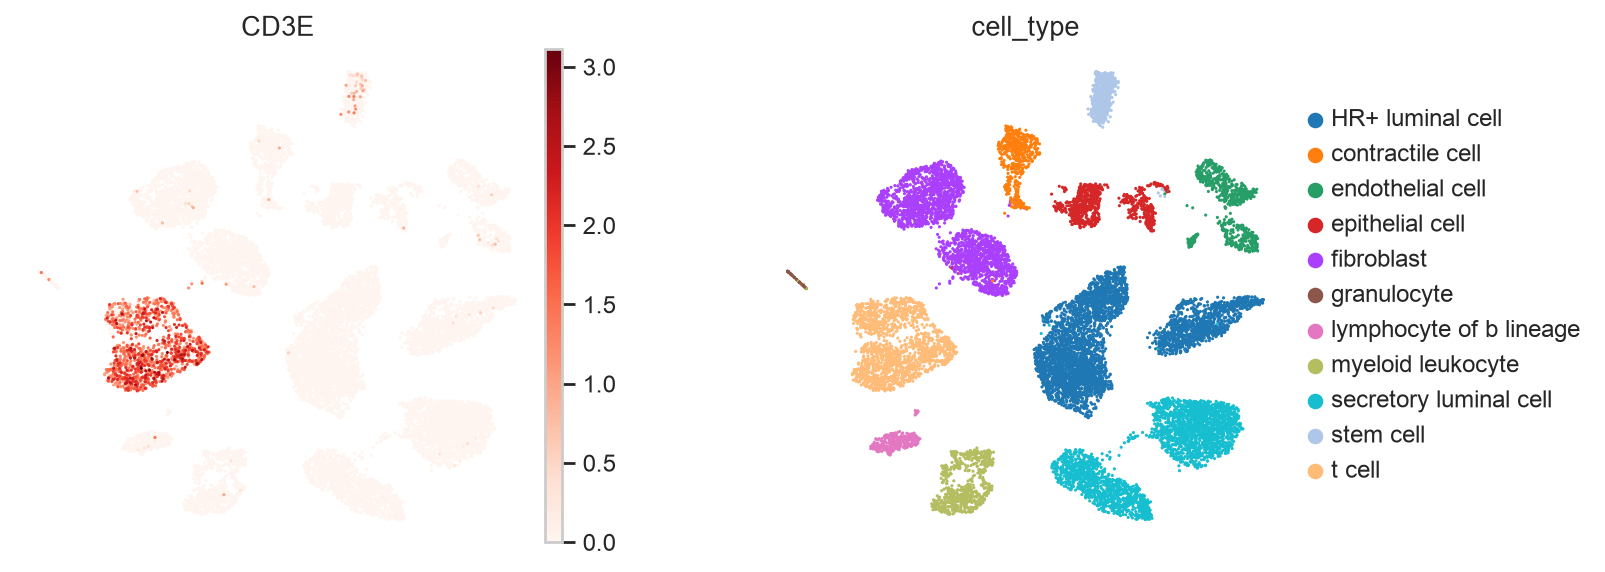

In [41]:
sc.pl.umap(adata, color=["CD3E", "cell_type"], cmap="Reds", size=8, wspace=0.3)

## 7. Summary and saving

What we did:

1. Loaded an `AnnData` object and checked that `X` contains **raw integer counts**.
2. Explored the metadata: 11 cell types with strong **class imbalance** and **different compositions between donors**.
3. Described the count matrix: **>90 % zeros**, library sizes spanning 2 orders of magnitude and differing between donors/samples, and an
   **overdispersed mean–variance** relationship.
4. Performed **QC** with simple fixed thresholds and removed rarely detected genes.
5. **Normalised**, log-transformed, selected HVGs, scaled, and computed **PCA** and **UMAP** from the counts; observed a **donor effect**.
6. Visualised **marker genes** for each cell type.

We save the processed object so it can be used in the next exercises (e.g. training a cell-type classifier).

In [42]:
adata.write_h5ad("tabula_sapiens_breast_processed.h5ad", compression="gzip")
adata

AnnData object with n_obs × n_vars = 14922 × 30497
    obs: 'donor_id', 'tissue_in_publication', 'method', 'assay_ontology_term_id', 'sample_id', 'replicate', '10X_run', 'ambient_removal', 'compartment', 'cell_type', 'free_annotation', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'ethnicity_original', 'sample_number', 'suspension_type', 'tissue_type', 'disease_ontology_term_id', 'is_primary_data', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'log1p_total_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'qc_fail', 'total_counts_normalised'
    var: 'ensembl_id', 'genome', 'mt', 'feature_is_filtered', 